# Part A

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import random
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam
from cycler import cycler
from statsmodels.tsa.seasonal import STL
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.linear_model import SGDClassifier
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
)
import copy
import time
from collections import Counter

2025-04-28 11:26:36.352679: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1745835996.387093   31789 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1745835996.397389   31789 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-04-28 11:26:36.432249: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [3]:
# import csv
df = pd.read_csv("./archive/Edge-IIoTset dataset/Selected dataset for ML and DL/ML-EdgeIIoT-dataset.csv", parse_dates=['frame.time'])

/tmp/ipykernel_31789/3434952694.py:2: DtypeWarning: Columns (3,6,11,13,14,15,16,17,31,32,34,39,45,51,54,55) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("./archive/Edge-IIoTset dataset/Selected dataset for ML and DL/ML-EdgeIIoT-dataset.csv", parse_dates=['frame.time'])
/tmp/ipykernel_31789/3434952694.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df = pd.read_csv("./archive/Edge-IIoTset dataset/Selected dataset for ML and DL/ML-EdgeIIoT-dataset.csv", parse_dates=['frame.time'])


In [4]:
# Check data
print(df.head(5))
print(df.head(5))

  frame.time    ip.src_host ip.dst_host arp.dst.proto_ipv4  arp.opcode  \
0        6.0  192.168.0.152         0.0                0.0         0.0   
1        6.0  192.168.0.101         0.0                0.0         0.0   
2        6.0  192.168.0.152         0.0                0.0         0.0   
3        6.0  192.168.0.101         0.0                0.0         0.0   
4        6.0  192.168.0.152         0.0                0.0         0.0   

   arp.hw.size arp.src.proto_ipv4  icmp.checksum  icmp.seq_le  \
0          0.0                0.0            0.0          0.0   
1          0.0                0.0            0.0          0.0   
2          0.0                0.0            0.0          0.0   
3          0.0                0.0            0.0          0.0   
4          0.0                0.0            0.0          0.0   

   icmp.transmit_timestamp  ...  mqtt.proto_len mqtt.protoname  mqtt.topic  \
0                      0.0  ...             0.0            0.0         0.0   
1       

In [5]:
# count attack types
attack_type = df.value_counts('Attack_type')

print(attack_type.index)
print(attack_type.values)

Index(['Normal', 'DDoS_UDP', 'DDoS_ICMP', 'Ransomware', 'DDoS_HTTP',
       'SQL_injection', 'Uploading', 'DDoS_TCP', 'Backdoor',
       'Vulnerability_scanner', 'Port_Scanning', 'XSS', 'Password', 'MITM',
       'Fingerprinting'],
      dtype='object', name='Attack_type')
[24301 14498 14090 10925 10561 10311 10269 10247 10195 10076 10071 10052
  9989  1214  1001]


In [6]:
df.shape
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 157800 entries, 0 to 157799
Data columns (total 63 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   frame.time                 157800 non-null  object 
 1   ip.src_host                157800 non-null  object 
 2   ip.dst_host                157800 non-null  object 
 3   arp.dst.proto_ipv4         157800 non-null  object 
 4   arp.opcode                 157800 non-null  float64
 5   arp.hw.size                157800 non-null  float64
 6   arp.src.proto_ipv4         157800 non-null  object 
 7   icmp.checksum              157800 non-null  float64
 8   icmp.seq_le                157800 non-null  float64
 9   icmp.transmit_timestamp    157800 non-null  float64
 10  icmp.unused                157800 non-null  float64
 11  http.file_data             157800 non-null  object 
 12  http.content_length        157800 non-null  float64
 13  http.request.uri.query     15

In [7]:
df["Local_time"] = pd.to_datetime(df["frame.time"], utc=True, errors='coerce')
df = df.dropna(subset=['Local_time'])
df = df.drop(['frame.time'], axis = 1)

# Drop rows with NaN values if they exist after conversion
df = df.dropna()

df.shape
df.info()

/tmp/ipykernel_31789/2605358595.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["Local_time"] = pd.to_datetime(df["frame.time"], utc=True, errors='coerce')


<class 'pandas.core.frame.DataFrame'>
Index: 142095 entries, 1214 to 157799
Data columns (total 63 columns):
 #   Column                     Non-Null Count   Dtype              
---  ------                     --------------   -----              
 0   ip.src_host                142095 non-null  object             
 1   ip.dst_host                142095 non-null  object             
 2   arp.dst.proto_ipv4         142095 non-null  object             
 3   arp.opcode                 142095 non-null  float64            
 4   arp.hw.size                142095 non-null  float64            
 5   arp.src.proto_ipv4         142095 non-null  object             
 6   icmp.checksum              142095 non-null  float64            
 7   icmp.seq_le                142095 non-null  float64            
 8   icmp.transmit_timestamp    142095 non-null  float64            
 9   icmp.unused                142095 non-null  float64            
 10  http.file_data             142095 non-null  object        

In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
arp.opcode,142095.0,1.576410e-02,1.577650e-01,0.0,0.0,0.000000e+00,0.000000e+00,2.000000e+00
arp.hw.size,142095.0,6.646258e-02,6.279817e-01,0.0,0.0,0.000000e+00,0.000000e+00,6.000000e+00
icmp.checksum,142095.0,3.384093e+03,1.169543e+04,0.0,0.0,0.000000e+00,0.000000e+00,6.553200e+04
icmp.seq_le,142095.0,3.275321e+03,1.146567e+04,0.0,0.0,0.000000e+00,0.000000e+00,6.551700e+04
icmp.transmit_timestamp,142095.0,4.494089e+04,1.858954e+06,0.0,0.0,0.000000e+00,0.000000e+00,7.728902e+07
icmp.unused,142095.0,0.000000e+00,0.000000e+00,0.0,0.0,0.000000e+00,0.000000e+00,0.000000e+00
http.content_length,142095.0,1.634195e+01,2.419638e+02,0.0,0.0,0.000000e+00,0.000000e+00,8.365500e+04
http.response,142095.0,5.080404e-02,2.195981e-01,0.0,0.0,0.000000e+00,0.000000e+00,1.000000e+00
http.tls_port,142095.0,0.000000e+00,0.000000e+00,0.0,0.0,0.000000e+00,0.000000e+00,0.000000e+00
tcp.ack,142095.0,7.951399e+07,3.258481e+08,0.0,1.0,6.000000e+00,7.030000e+02,2.147333e+09


In [9]:
# Extract date-based features
df['year'] = df['Local_time'].dt.year
df['month'] = df['Local_time'].dt.month
df['day'] = df['Local_time'].dt.day
df['hour'] = df['Local_time'].dt.hour
df['weekday'] = df['Local_time'].dt.weekday  # 0=Monday, 6=Sunday

# Check for duplicates
df = df.drop_duplicates()


In [10]:
from sklearn.preprocessing import LabelEncoder

# Label encoding for 'Attack_type'
label_encoder = LabelEncoder()
df['Attack_type_encoded'] = label_encoder.fit_transform(df['Attack_type'])

In [11]:
# count attack labels
attack_label = df.value_counts('Attack_label')

print(attack_label.index)     # these will be our bar labels
print(attack_label.values)    # these will be the heights of the bars

Index([1, 0], dtype='int64', name='Attack_label')
[117794  24301]


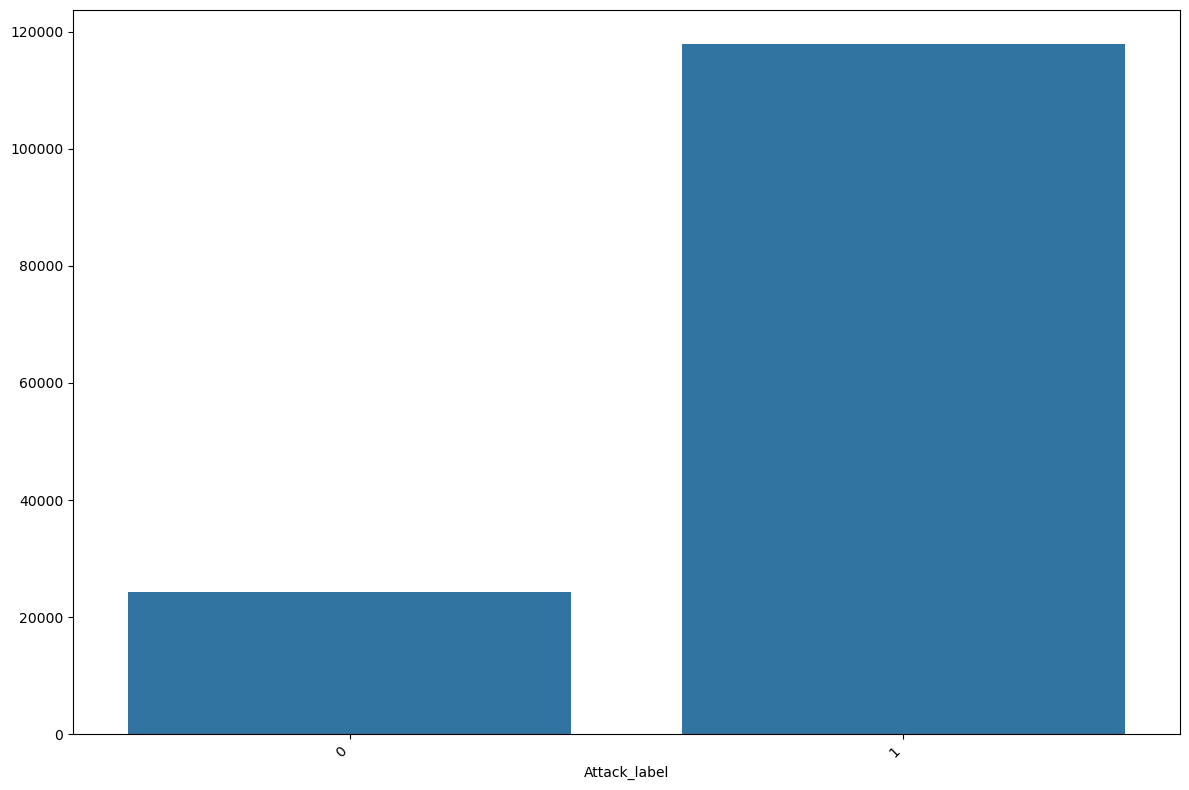

In [12]:
# Create a seaborn barplot
plt.figure(figsize=(12, 8))
sns.barplot(x=attack_label.index, y=attack_label.values)

# Rotate x-axis labels
plt.xticks(rotation=45, ha="right")

plt.tight_layout()  # Automatically adjust layout
plt.show()

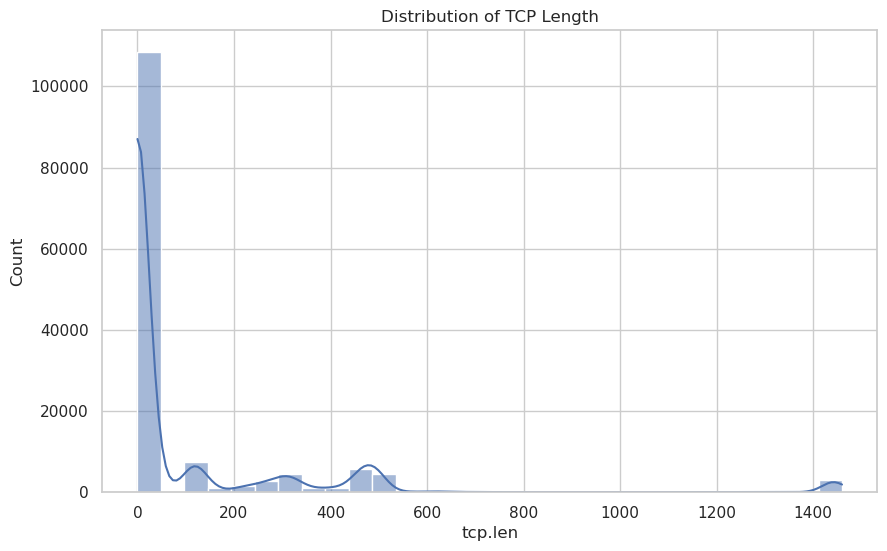

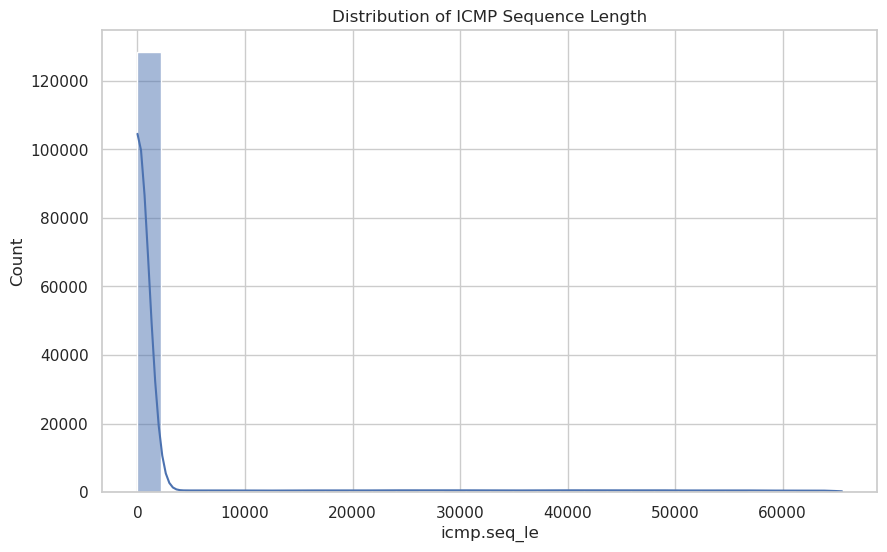

In [13]:
# Set plot style
sns.set(style="whitegrid")

# Plot the distribution tcp length
plt.figure(figsize=(10, 6))
sns.histplot(df['tcp.len'], bins=30, kde=True)
plt.title('Distribution of TCP Length')
plt.show()

# Plot the distribution of 'icmp.seq_le'
plt.figure(figsize=(10, 6))
sns.histplot(df['icmp.seq_le'], bins=30, kde=True)
plt.title('Distribution of ICMP Sequence Length')
plt.show()


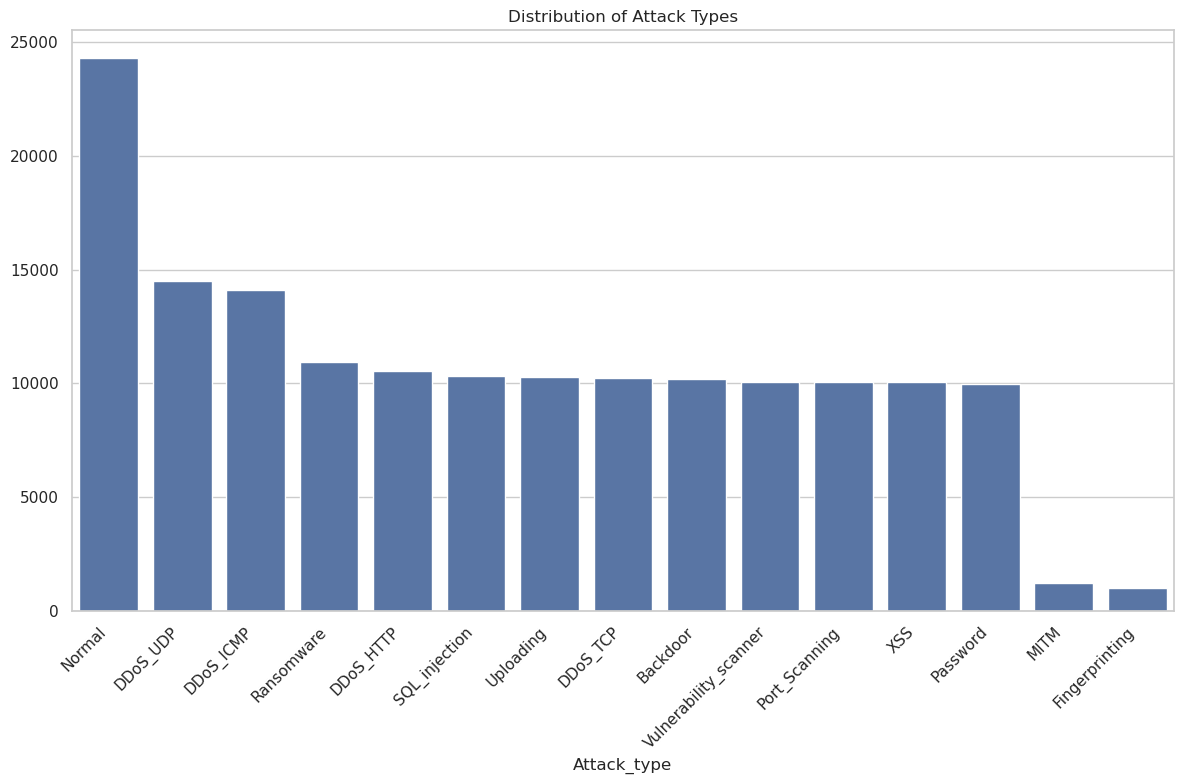

In [14]:
# Create a seaborn barplot
plt.figure(figsize=(12, 8))
sns.barplot(x=attack_type.index, y=attack_type.values)

# Rotate x-axis labels
plt.xticks(rotation=45, ha="right")
plt.title('Distribution of Attack Types')
plt.tight_layout()  # Automatically adjust layout
plt.show()

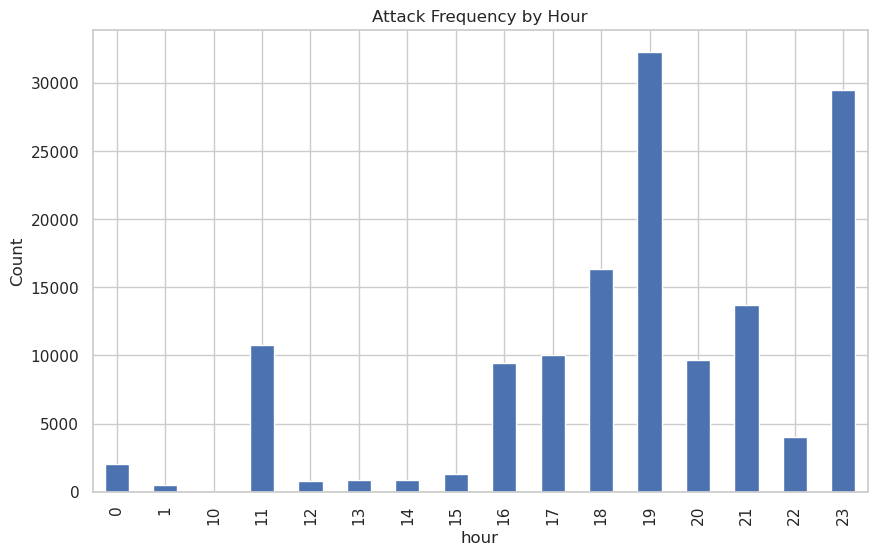

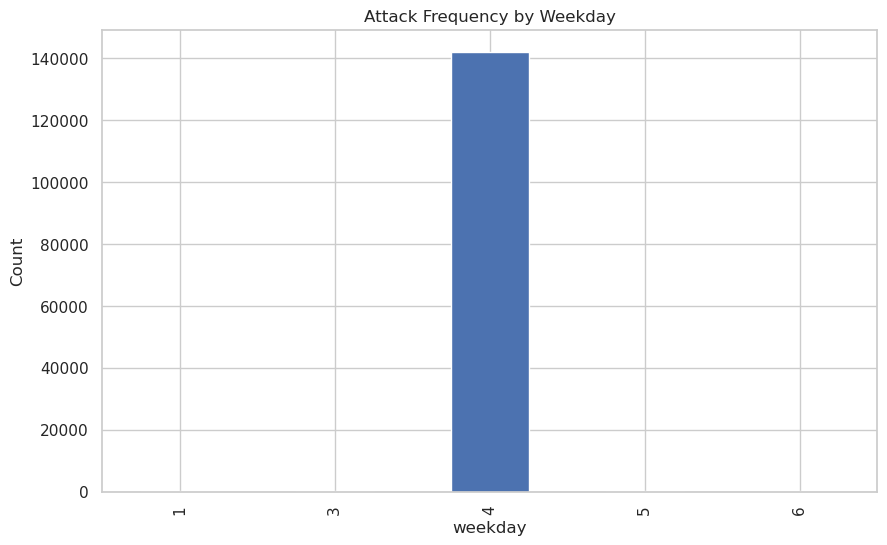

In [15]:
# Plot the frequency of attacks by hour
plt.figure(figsize=(10, 6))
df.groupby('hour')['Attack_type'].count().plot(kind='bar')
plt.title('Attack Frequency by Hour')
plt.ylabel('Count')
plt.show()

# Plot the frequency of attacks by day of the week
plt.figure(figsize=(10, 6))
df.groupby('weekday')['Attack_type'].count().plot(kind='bar')
plt.title('Attack Frequency by Weekday')
plt.ylabel('Count')
plt.show()

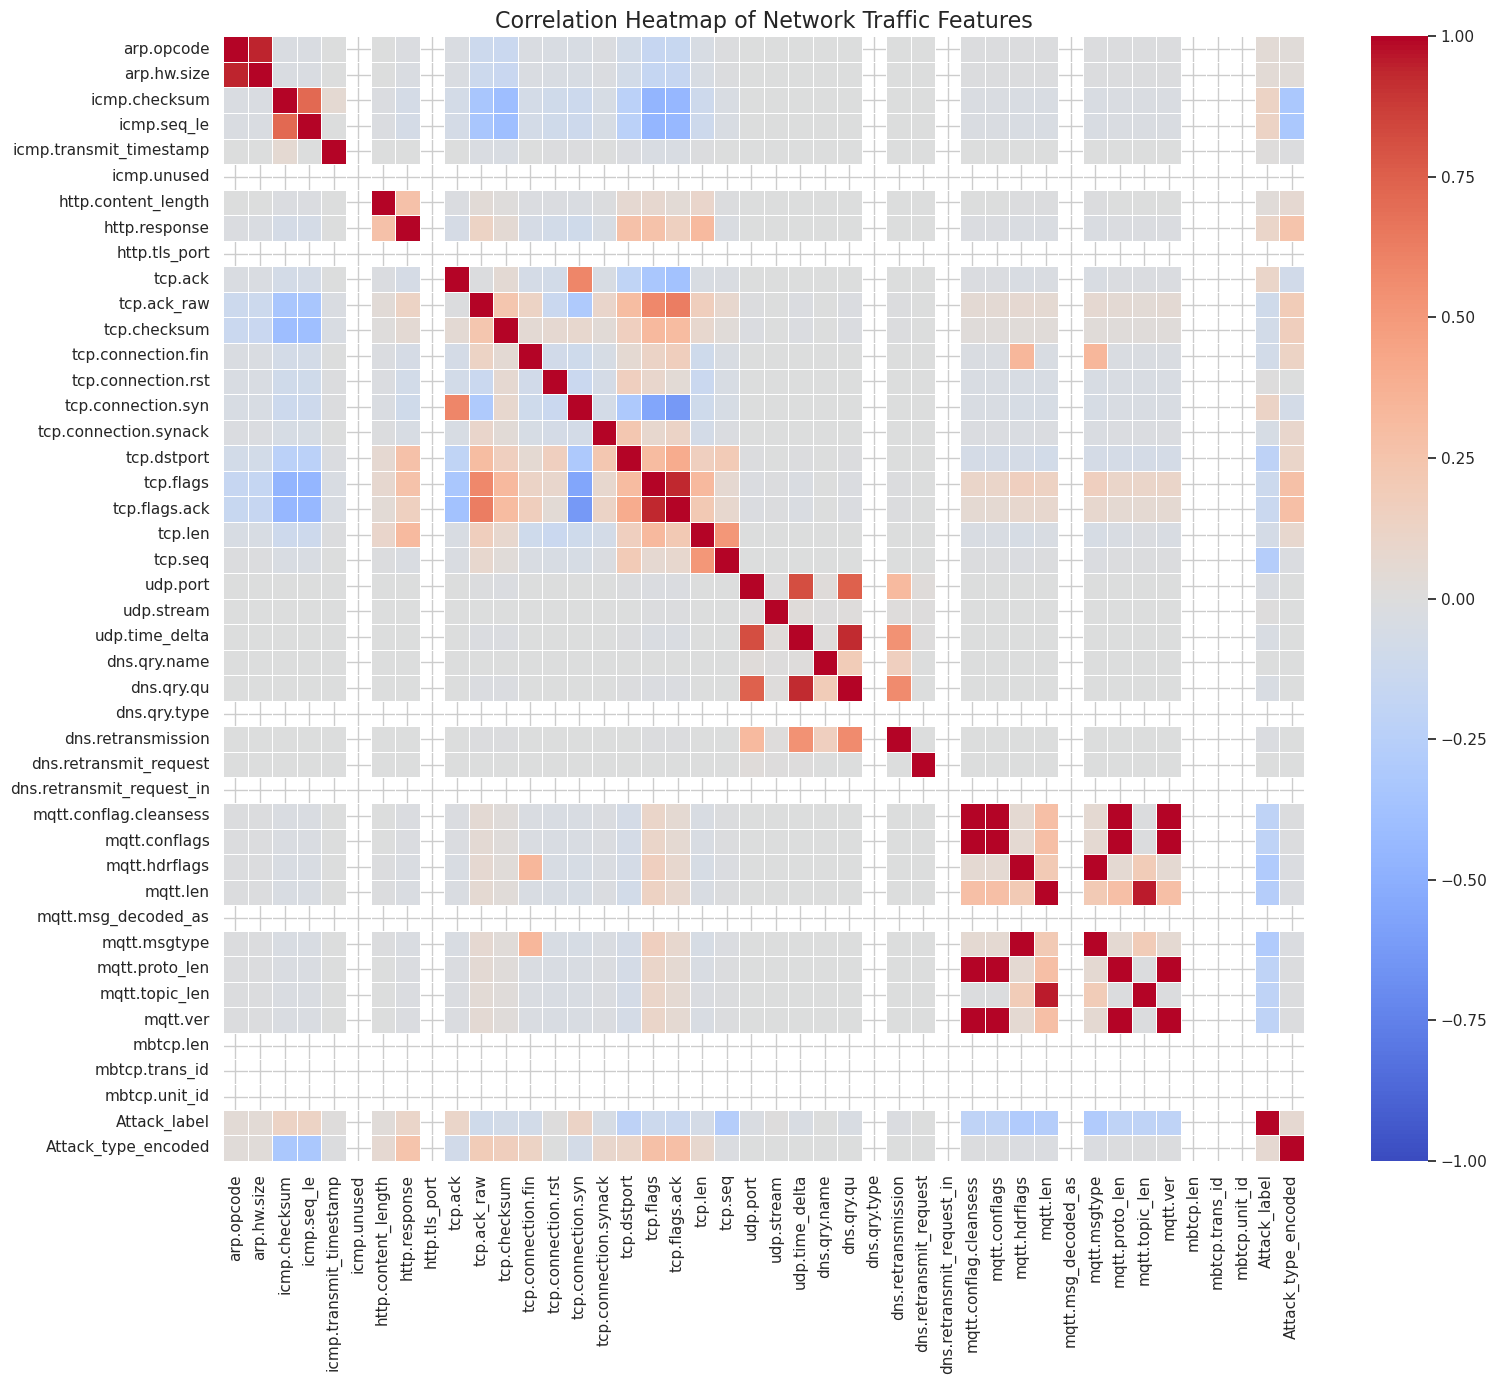

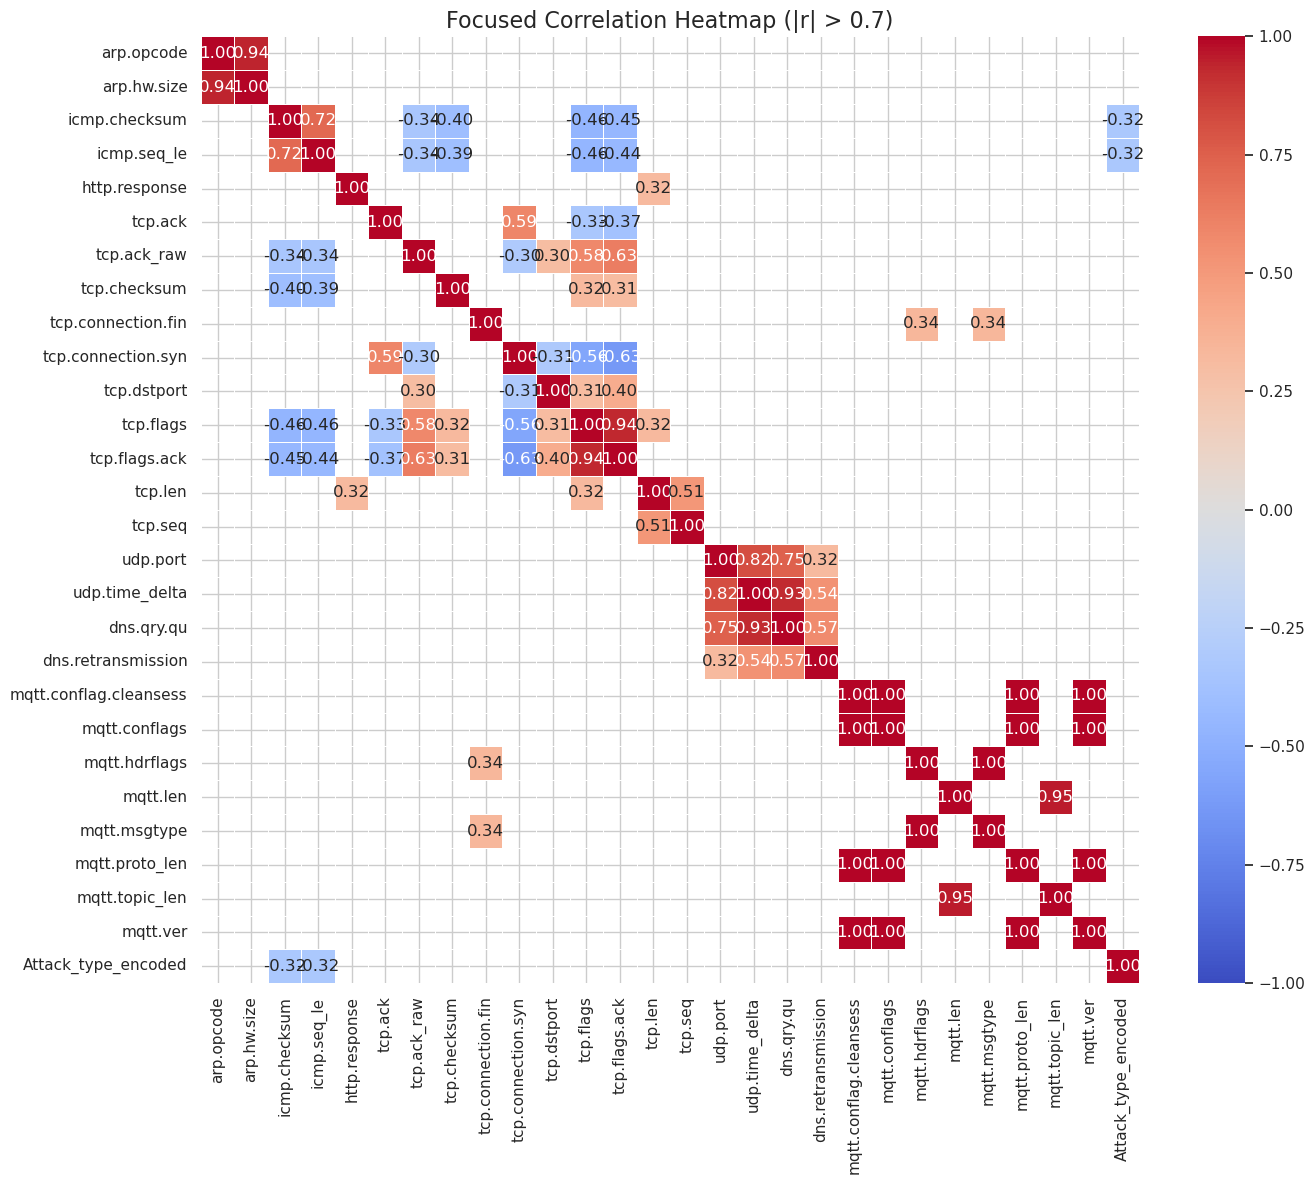

Correlations with Attack_label:
Attack_label                 1.000000
icmp.checksum                0.131425
icmp.seq_le                  0.129750
tcp.connection.syn           0.122058
http.response                0.105080
tcp.ack                      0.103394
Attack_type_encoded          0.066550
arp.hw.size                  0.040571
arp.opcode                   0.039935
http.content_length          0.030676
icmp.transmit_timestamp      0.010981
tcp.connection.rst           0.007330
udp.stream                   0.001641
dns.retransmit_request      -0.005841
dns.qry.name                -0.005847
dns.retransmission          -0.017790
udp.port                    -0.029127
dns.qry.qu                  -0.031455
udp.time_delta              -0.033466
tcp.connection.synack       -0.053865
tcp.len                     -0.063317
tcp.connection.fin          -0.078401
tcp.checksum                -0.084197
tcp.ack_raw                 -0.101385
tcp.flags                   -0.122270
tcp.flags.ack     

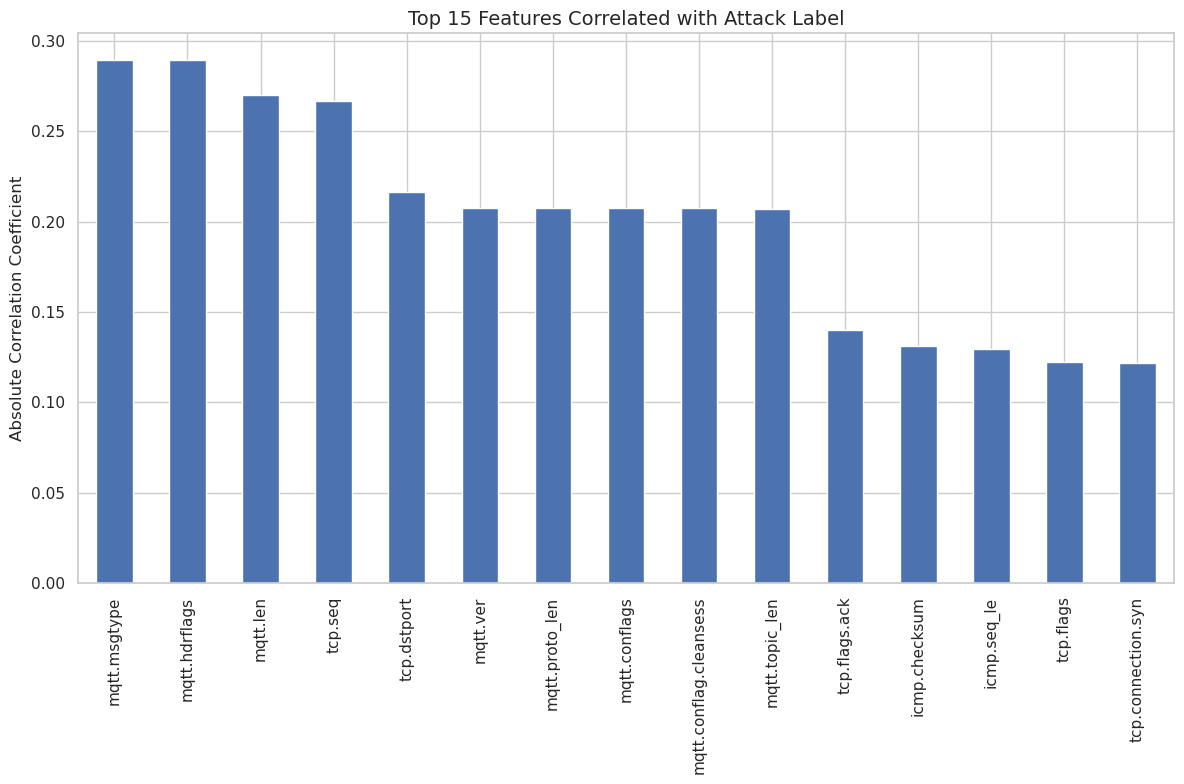

In [16]:
# Select only numeric columns for correlation analysis
numeric_columns = df.select_dtypes(include=['float64', 'int64']).columns
numeric_df = df[numeric_columns]

# Calculate correlation matrix
correlation_matrix = numeric_df.corr()

# Visualize the correlation matrix as a heatmap
plt.figure(figsize=(16, 14))
sns.heatmap(
    correlation_matrix, 
    annot=False,
    cmap='coolwarm', 
    vmin=-1, 
    vmax=1,
    linewidths=0.5
)
plt.title('Correlation Heatmap of Network Traffic Features', fontsize=16)
plt.tight_layout()
plt.show()

# thresholding
threshold = 0.3
high_corr = correlation_matrix.abs() > threshold
high_corr_matrix = correlation_matrix.where(high_corr)

# Filter out columns with no high correlations
cols_to_keep = [col for col in high_corr_matrix.columns if high_corr_matrix[col].count() > 1]
focused_matrix = high_corr_matrix.loc[cols_to_keep, cols_to_keep]

# Create a more focused heatmap
plt.figure(figsize=(14, 12))
sns.heatmap(
    focused_matrix,
    annot=True,
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    fmt=".2f"
)
plt.title('Focused Correlation Heatmap (|r| > 0.7)', fontsize=16)
plt.tight_layout()
plt.show()

attack_corr = correlation_matrix['Attack_label'].sort_values(ascending=False)
print("Correlations with Attack_label:")
print(attack_corr)

# Visualize top 15 features correlated with attacks
plt.figure(figsize=(12, 8))
attack_corr.drop('Attack_label').abs().sort_values(ascending=False).head(15).plot(kind='bar')
plt.title('Top 15 Features Correlated with Attack Label', fontsize=14)
plt.ylabel('Absolute Correlation Coefficient')
plt.tight_layout()
plt.show()

In [17]:

# Select only numeric columns for correlation analysis
numeric_columns = df.select_dtypes(include=['float64', 'int64']).columns
numeric_df = df[numeric_columns]

# Calculate correlation matrix
correlation_matrix = numeric_df.corr()

#  Remove diagonal values
np.fill_diagonal(correlation_matrix.values, np.nan)

# Find columns with at least one significant correlation
correlation_threshold = 0.3

# For each column, check if it has any correlations above the threshold
has_high_correlation = (correlation_matrix.abs() > correlation_threshold).any()
high_corr_columns = has_high_correlation[has_high_correlation].index.tolist()

# Create a new DataFrame with only the high-correlation columns
important_non_numeric = ['Attack_type', 'Local_time'] 
# Always keep the Attack_label column even if it has low correlation
if 'Attack_label' in df.columns and 'Attack_label' not in high_corr_columns:
    high_corr_columns.append('Attack_label')

# Combine numeric high correlation columns with important non-numeric columns
columns_to_keep = high_corr_columns + [col for col in important_non_numeric if col in df.columns]

# Create the filtered DataFrame
filtered_df = df[columns_to_keep]

# Print information about the filtering
print(f"Original DataFrame shape: {df.shape}")
print(f"Filtered DataFrame shape: {filtered_df.shape}")
print(f"Removed {df.shape[1] - filtered_df.shape[1]} columns with low correlation")

# Display the remaining high-correlation columns
print("\nHigh correlation columns kept:")
for col in high_corr_columns:
    print(f"- {col}")

Original DataFrame shape: (142095, 69)
Filtered DataFrame shape: (142095, 31)
Removed 38 columns with low correlation

High correlation columns kept:
- arp.opcode
- arp.hw.size
- icmp.checksum
- icmp.seq_le
- http.response
- tcp.ack
- tcp.ack_raw
- tcp.checksum
- tcp.connection.fin
- tcp.connection.syn
- tcp.dstport
- tcp.flags
- tcp.flags.ack
- tcp.len
- tcp.seq
- udp.port
- udp.time_delta
- dns.qry.qu
- dns.retransmission
- mqtt.conflag.cleansess
- mqtt.conflags
- mqtt.hdrflags
- mqtt.len
- mqtt.msgtype
- mqtt.proto_len
- mqtt.topic_len
- mqtt.ver
- Attack_type_encoded
- Attack_label


In [18]:
df = []

print(filtered_df.shape)
print(filtered_df.info())

(142095, 31)
<class 'pandas.core.frame.DataFrame'>
Index: 142095 entries, 1214 to 157799
Data columns (total 31 columns):
 #   Column                  Non-Null Count   Dtype              
---  ------                  --------------   -----              
 0   arp.opcode              142095 non-null  float64            
 1   arp.hw.size             142095 non-null  float64            
 2   icmp.checksum           142095 non-null  float64            
 3   icmp.seq_le             142095 non-null  float64            
 4   http.response           142095 non-null  float64            
 5   tcp.ack                 142095 non-null  float64            
 6   tcp.ack_raw             142095 non-null  float64            
 7   tcp.checksum            142095 non-null  float64            
 8   tcp.connection.fin      142095 non-null  float64            
 9   tcp.connection.syn      142095 non-null  float64            
 10  tcp.dstport             142095 non-null  float64            
 11  tcp.flags      

In [19]:
df = filtered_df

In [20]:
# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)
random.seed(42)

In [21]:
def preprocess_data(df):
    # Make a copy of the dataframe
    df_copy = df.copy()
    
    # convert mixed type columns to string to avoid OneHotEncoder errors
    for col in df_copy.select_dtypes(include=['object']).columns:
        df_copy[col] = df_copy[col].astype(str)
    
    # handle missing values in object columns
    for col in df_copy.select_dtypes(include=['object']).columns:
        df_copy[col].fillna('missing', inplace=True)
    
    # Handle missing values in numeric columns
    for col in df_copy.select_dtypes(include=['float64', 'int32']).columns:
        df_copy[col].fillna(0, inplace=True)
    
    if 'Local_time' in df_copy.columns:
        df_copy = df_copy.drop('Local_time', axis=1)  # Drop local time as already have year, month, day, etc.
    
    # Extract features and target
    X = df_copy.drop(['Attack_type'], axis=1)
    y = df_copy['Attack_type']
    
    # Split the data
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
    
    return X_train, X_test, y_train, y_test, X, y

In [22]:
def build_preprocessor(X_train):
    # Identify categorical and numerical columns
    categorical_cols = X_train.select_dtypes(include=['object']).columns.tolist()
    numerical_cols = X_train.select_dtypes(include=['float64', 'int32']).columns.tolist()
    
    # Create preprocessing pipelines for both numerical and categorical data
    numerical_transformer = Pipeline(steps=[
        ('scaler', StandardScaler())
    ])
    
    # for categorical data with high cardinality, set max_categories
    categorical_transformer = Pipeline(steps=[
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False, max_categories=30))
    ])
    
    # Combine preprocessing steps
    preprocessor = ColumnTransformer(
        transformers=[
            ('num', numerical_transformer, numerical_cols),
            ('cat', categorical_transformer, categorical_cols)
        ],
        n_jobs=1,
        verbose=True
    )
    
    return preprocessor

In [23]:
def train_model(X_train, y_train, preprocessor):
    # knn model
    knn_model = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', KNeighborsClassifier(n_neighbors=5, n_jobs=1))
    ])
    
    # Random Forest Classifier model
    randomforest_model = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', RandomForestClassifier(n_estimators=50, max_depth=15, 
                                             min_samples_split=10, random_state=42, 
                                             n_jobs=1, verbose=1))
    ])
    
    # sgd model
    sgd_model = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', SGDClassifier(loss='hinge', penalty='l2', max_iter=15, random_state=42))
    ])
    
    # mlp model
    mlp_model = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', MLPClassifier(hidden_layer_sizes=(100,), max_iter=15, random_state=42))
    ])
    
    # Fit all models
    print("Starting model fitting...")
    knn_model.fit(X_train, y_train)
    print("training random")
    randomforest_model.fit(X_train, y_train)
    print("training sgd")
    sgd_model.fit(X_train, y_train)
    print("training mlp")
    mlp_model.fit(X_train, y_train)
    print("Model training complete!")
    
    return knn_model, randomforest_model, sgd_model, mlp_model

In [24]:
def evaluate_model(model, X_test, y_test):
    print("Making predictions...")
    y_pred = model.predict(X_test)
    
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, digits=4))
    
    print(f"\nAccuracy: {accuracy_score(y_test, y_pred):.4f}")
    
    # Create confusion matrix
    print("Generating confusion matrix...")
    cm = confusion_matrix(y_test, y_pred)
    
    # Get unique attack types
    attack_types = np.unique(y_test)
    
    plt_height = max(8, len(attack_types) * 0.5)
    plt.figure(figsize=(10, plt_height))
    
    # Plot confusion matrix
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=attack_types,
                yticklabels=attack_types)
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title('Confusion Matrix')
    plt.tight_layout()
    plt.show()
    
    return y_pred

In [25]:
def get_feature_importance(model, X_train, top_n=30):
    print("Extracting feature importance...")
    # Get the feature names after preprocessing
    feature_names = []
    
    # Add numerical feature names directly
    numerical_cols = X_train.select_dtypes(include=['float64', 'int32']).columns.tolist()
    feature_names.extend(numerical_cols)
    
    # Add placeholder names for categorical features
    categorical_cols = X_train.select_dtypes(include=['object']).columns.tolist()
    for col in categorical_cols:
        feature_names.append(f"{col}_encoded")
        
    # Get feature importance from the model
    feature_importance = model.named_steps['classifier'].feature_importances_
    
    # Create a DataFrame for feature importance
    # Use min length to avoid index errors if the transformed feature count differs
    min_length = min(len(feature_names), len(feature_importance))
    importance_df = pd.DataFrame({
        'feature': feature_names[:min_length],
        'importance': feature_importance[:min_length]
    })
    
    # Sort by importance
    importance_df = importance_df.sort_values('importance', ascending=False)
    
    # Visualize top features
    plt.figure(figsize=(12, 8))
    top_features = importance_df.head(top_n)
    sns.barplot(x='importance', y='feature', data=top_features)
    plt.title(f'Top {top_n} Feature Importance')
    plt.tight_layout()
    plt.show()
    
    return importance_df


Preprocessing data...
Building preprocessor...
Training model...
Starting model fitting...


/tmp/ipykernel_31789/2735930650.py:11: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_copy[col].fillna('missing', inplace=True)
/tmp/ipykernel_31789/2735930650.py:15: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try 

[ColumnTransformer] ........... (1 of 1) Processing num, total=   0.1s
training random
[ColumnTransformer] ........... (1 of 1) Processing num, total=   0.1s


[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:    9.5s


training sgd
[ColumnTransformer] ........... (1 of 1) Processing num, total=   0.0s


...

training mlp
[ColumnTransformer] ........... (1 of 1) Processing num, total=   0.0s


/home/shroudedsublet/anaconda3/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (15) reached and the optimization hasn't converged yet.
  warnings.warn(


Model training complete!
Evaluating knn...
Making predictions...

Classification Report:


/home/shroudedsublet/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/shroudedsublet/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/shroudedsublet/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", le

                       precision    recall  f1-score   support

             Backdoor     0.9359    0.9145    0.9251      3065
            DDoS_HTTP     0.5264    0.5986    0.5602      3231
            DDoS_ICMP     0.9995    0.9895    0.9945      4189
             DDoS_TCP     0.9032    0.8856    0.8943      3033
             DDoS_UDP     0.0000    0.0000    0.0000         2
       Fingerprinting     0.8289    0.6855    0.7504       318
               Normal     0.8559    0.8891    0.8722      7340
             Password     0.3094    0.2687    0.2876      3033
        Port_Scanning     0.8574    0.9456    0.8993      2976
           Ransomware     0.9131    0.8304    0.8698      3226
        SQL_injection     0.4939    0.5021    0.4979      3139
            Uploading     0.5148    0.4387    0.4737      3089
Vulnerability_scanner     0.8061    0.7883    0.7971      3037
                  XSS     0.4117    0.4615    0.4352      2951

             accuracy                         0.7344 

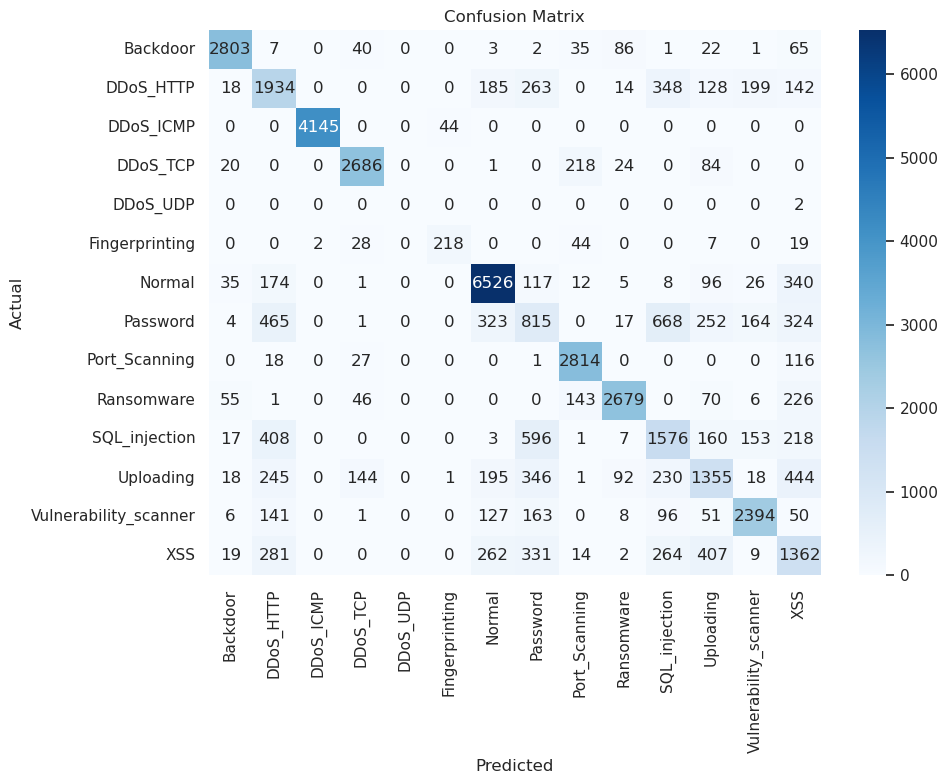

Evaluating randomforest...
Making predictions...


[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:    0.4s



Classification Report:


/home/shroudedsublet/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/shroudedsublet/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/shroudedsublet/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", le

                       precision    recall  f1-score   support

             Backdoor     0.9979    0.9220    0.9585      3065
            DDoS_HTTP     0.6569    0.8812    0.7527      3231
            DDoS_ICMP     1.0000    0.9998    0.9999      4189
             DDoS_TCP     1.0000    1.0000    1.0000      3033
             DDoS_UDP     0.0000    0.0000    0.0000         2
       Fingerprinting     0.9955    0.6918    0.8163       318
               Normal     0.9017    0.9920    0.9447      7340
             Password     0.7432    0.7349    0.7391      3033
        Port_Scanning     0.9199    0.9610    0.9400      2976
           Ransomware     0.8546    0.9200    0.8861      3226
        SQL_injection     0.8721    0.7388    0.7999      3139
            Uploading     0.9155    0.7893    0.8477      3089
Vulnerability_scanner     0.9936    0.9266    0.9589      3037
                  XSS     0.9317    0.6981    0.7981      2951

             accuracy                         0.8934 

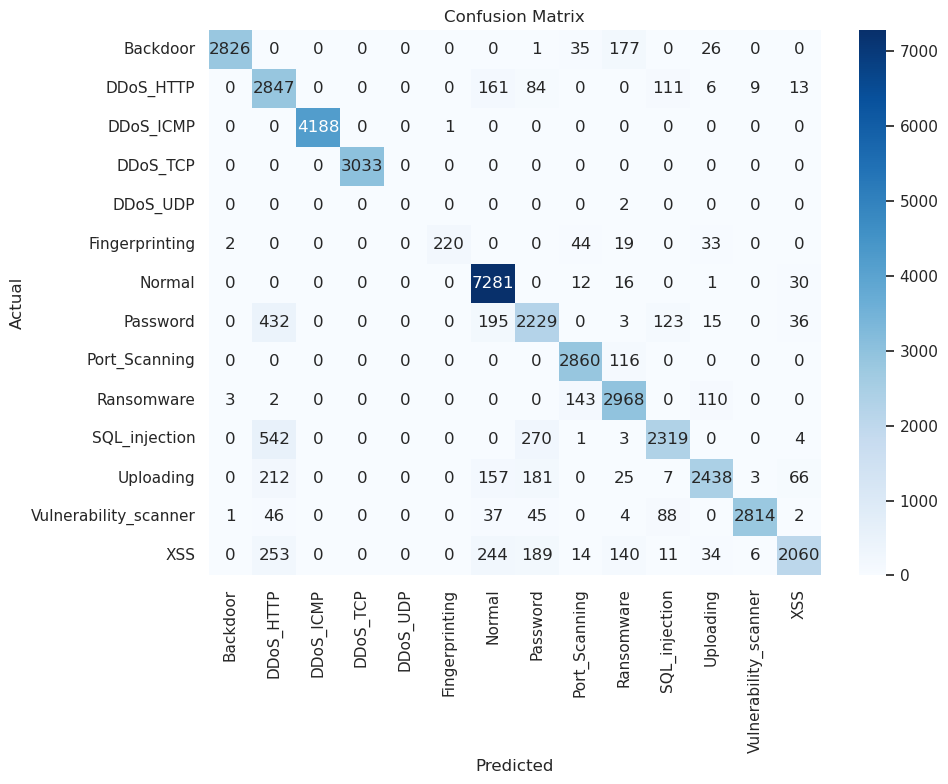

Evaluating sgd...
Making predictions...

Classification Report:


/home/shroudedsublet/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/shroudedsublet/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/shroudedsublet/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", le

                       precision    recall  f1-score   support

             Backdoor     0.4298    0.1856    0.2593      3065
            DDoS_HTTP     0.0000    0.0000    0.0000      3231
            DDoS_ICMP     0.9891    0.9971    0.9931      4189
             DDoS_TCP     0.5507    0.6647    0.6023      3033
             DDoS_UDP     0.0000    0.0000    0.0000         2
       Fingerprinting     0.8750    0.5283    0.6588       318
               Normal     0.6316    0.4657    0.5361      7340
             Password     0.1170    0.1560    0.1337      3033
        Port_Scanning     0.7032    0.9257    0.7992      2976
           Ransomware     0.1259    0.1556    0.1392      3226
        SQL_injection     0.1919    0.3320    0.2432      3139
            Uploading     0.1403    0.0777    0.1000      3089
Vulnerability_scanner     0.4435    0.7830    0.5663      3037
                  XSS     0.0604    0.0688    0.0643      2951

             accuracy                         0.4209 

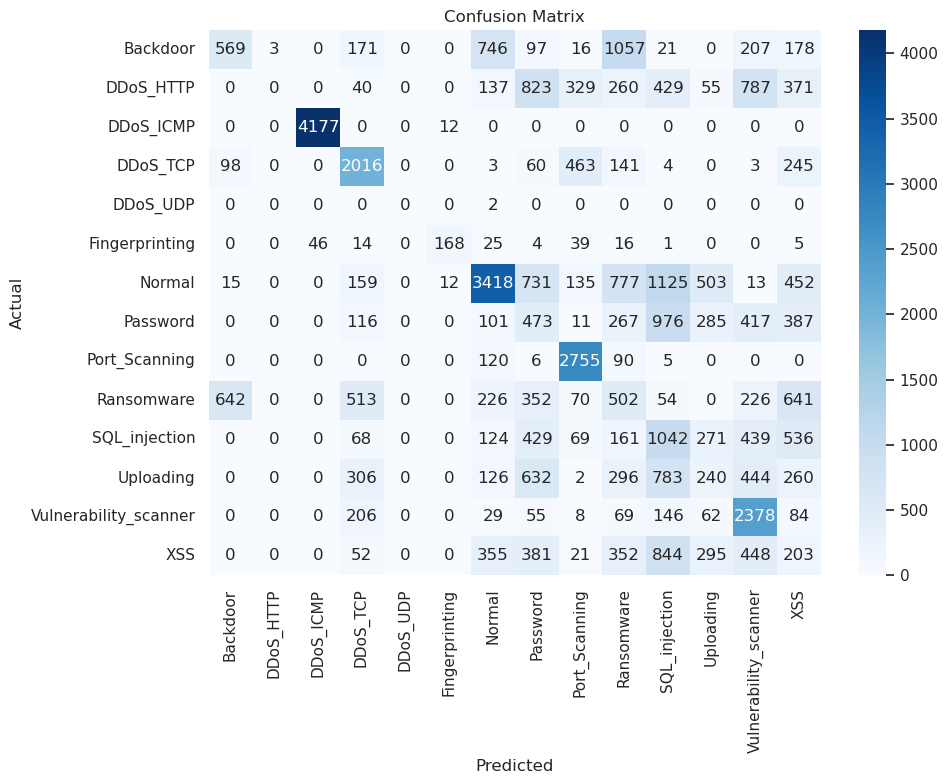

Evaluating mlp...
Making predictions...

Classification Report:


/home/shroudedsublet/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/shroudedsublet/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/shroudedsublet/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", le

                       precision    recall  f1-score   support

             Backdoor     0.7896    0.8483    0.8179      3065
            DDoS_HTTP     0.5574    0.5407    0.5489      3231
            DDoS_ICMP     1.0000    0.9881    0.9940      4189
             DDoS_TCP     0.8682    0.9209    0.8938      3033
             DDoS_UDP     0.0000    0.0000    0.0000         2
       Fingerprinting     0.8154    0.6667    0.7336       318
               Normal     0.7701    0.8736    0.8186      7340
             Password     0.3030    0.3627    0.3302      3033
        Port_Scanning     0.8762    0.9207    0.8979      2976
           Ransomware     0.6906    0.8338    0.7555      3226
        SQL_injection     0.4773    0.4935    0.4853      3139
            Uploading     0.3995    0.3341    0.3639      3089
Vulnerability_scanner     0.8039    0.8357    0.8195      3037
                  XSS     0.5377    0.1135    0.1875      2951

             accuracy                         0.7011 

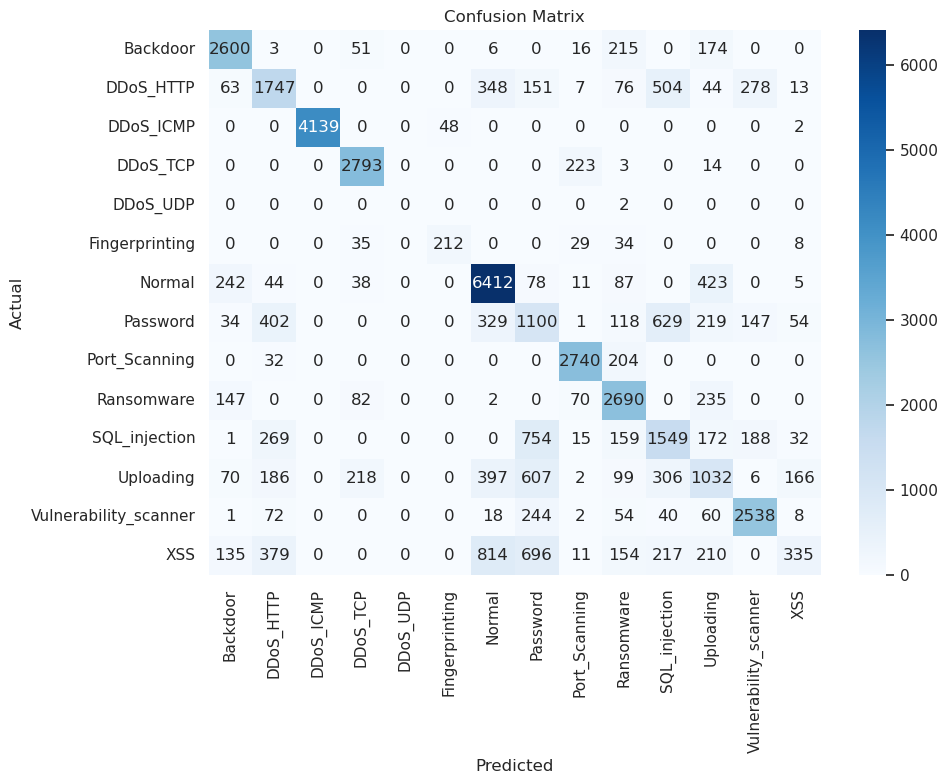

Extracting feature importancerandomforest_model...
Extracting feature importance...


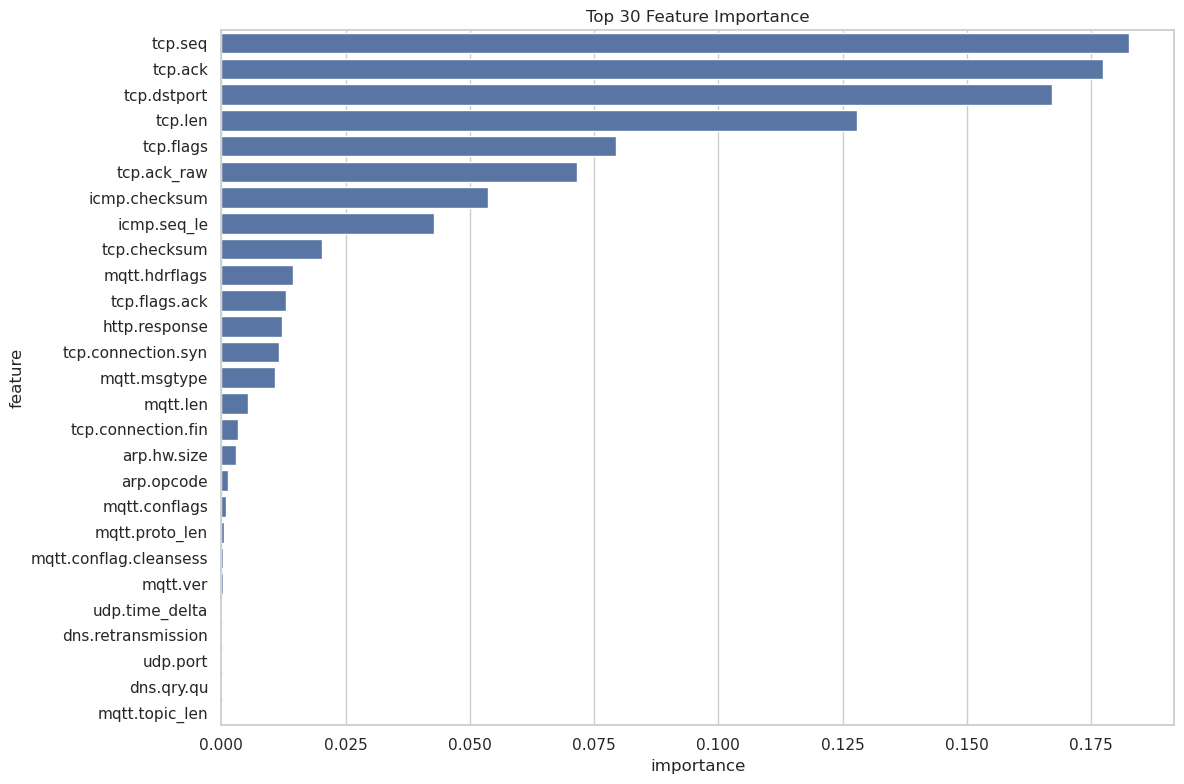

In [26]:
print("Preprocessing data...")
X_train, X_test, y_train, y_test, X, y = preprocess_data(df)

print("Building preprocessor...")
preprocessor = build_preprocessor(X_train)

print("Training model...")
knn_model, randomforest_model, sgd_model, mlp_model = train_model(X_train, y_train, preprocessor)

print("Evaluating knn...")
y_pred = evaluate_model(knn_model, X_test, y_test)

print("Evaluating randomforest...")
y_pred = evaluate_model(randomforest_model, X_test, y_test)

print("Evaluating sgd...")
y_pred = evaluate_model(sgd_model, X_test, y_test)

print("Evaluating mlp...")
y_pred = evaluate_model(mlp_model, X_test, y_test)

print("Extracting feature importancerandomforest_model...")
importance_df = get_feature_importance(randomforest_model, X_train)

# Part B

In [28]:
def targeted_label_poisoning(y_train, X_train, original_model, benign_label="Normal", percentages=[5, 10, 15, 20, 25], random_state=42):
    np.random.seed(random_state)
    
    # Make a copy of the original training labels
    y_train = y_train.copy()
    
    # Get all unique labels
    unique_labels = y_train.unique()
    
    # Identify attack labels (all labels except benign)
    attack_labels = [label for label in unique_labels if label != benign_label]
    
    # Get indices of attack samples
    attack_indices = y_train[y_train != benign_label].index
    
    # Initialize dictionary to store poisoned labels for each percentage
    poisoned_labels_dict = {}
    
    # Get predictions and probabilities from the model to identify samples to poison
    # These will be samples the model is confident about which makes poisoning more effective
    try:
        # Try to get prediction probabilities if the model supports it
        y_pred_proba = original_model.predict_proba(X_train.loc[attack_indices])
        confidence_scores = np.max(y_pred_proba, axis=1)
        
        # Calculate influence scores: higher confidence means higher impact when poisoned
        influence_scores = confidence_scores
    except:
        # if predict_proba not available, use random selection
        influence_scores = np.random.random(len(attack_indices))
    
    # Sort attack indices by influence score
    sorted_attack_indices = [index for _, index in 
                             sorted(zip(influence_scores, attack_indices), 
                                   reverse=True)]
    
    # Generate poisoned datasets for each percentage
    for percentage in percentages:
        # Calculate number of samples to poison
        num_samples_to_poison = int(len(y_train) * percentage / 100)
        
        # Make a copy of the original labels
        poisoned_labels = y_train.copy()
        
        # Select the most influential samples to poison
        indices_to_poison = sorted_attack_indices[:num_samples_to_poison]
        
        # Change attack labels to benign
        poisoned_labels.loc[indices_to_poison] = benign_label
        
        # Store the poisoned labels
        poisoned_labels_dict[percentage] = poisoned_labels
        
        print(f"Created poisoned dataset with {percentage}% poisoning: {num_samples_to_poison} samples modified")
        
    return poisoned_labels_dict

In [29]:
def strategic_label_poisoning(y_train, X_train, original_model, percentages=[5, 10, 15, 20, 25], random_state=42):
    np.random.seed(random_state)
    
    # Make a copy of the original training labels
    y_train = y_train.copy()
    
    # Get all unique labels
    unique_labels = y_train.unique()
    
    # Count frequencies of each class
    class_counts = Counter(y_train)
    
    # Identify minority attack types
    total_samples = len(y_train)
    minority_threshold = 0.05  # Classes with less than 5% of samples
    minority_classes = [label for label, count in class_counts.items() 
                        if count/total_samples < minority_threshold and label != "Normal"]
    
    # Get indices of samples from minority classes
    minority_indices = y_train[y_train.isin(minority_classes)].index.tolist()
    
    # Get indices of all attack samples
    attack_indices = y_train[y_train != "Normal"].index.tolist()
    
    # Initialize dictionary to store poisoned labels for each percentage
    poisoned_labels_dict = {}
    
    # For each percentage, create a poisoned dataset
    for percentage in percentages:
        # Calculate number of samples to poison
        num_samples_to_poison = int(len(y_train) * percentage / 100)
        
        # Make a copy of the original labels
        poisoned_labels = y_train.copy()
        
        # Split poisoning between minority classes and general attacks
        minority_portion = min(len(minority_indices), int(num_samples_to_poison * 0.6))
        general_portion = num_samples_to_poison - minority_portion
        
        # Select samples to poison
        minority_to_poison = np.random.choice(minority_indices, 
                                             size=minority_portion, 
                                             replace=False)
        
        remaining_attack_indices = list(set(attack_indices) - set(minority_to_poison))
        general_to_poison = np.random.choice(remaining_attack_indices, 
                                           size=min(general_portion, len(remaining_attack_indices)), 
                                           replace=False)
        
        # Combine indices to poison
        indices_to_poison = np.concatenate([minority_to_poison, general_to_poison])
        
        # Set all these to "Normal" (benign)
        poisoned_labels.loc[indices_to_poison] = "Normal"
        
        # Store the poisoned labels
        poisoned_labels_dict[percentage] = poisoned_labels
        
        print(f"Created poisoned dataset with {percentage}% poisoning: {num_samples_to_poison} samples modified")
        
    return poisoned_labels_dict

In [30]:
def random_label_flipping(y_train, percentages=[5, 10, 15, 20, 25], random_state=42):
    np.random.seed(random_state)
    
    # Get indices of attack samples
    attack_indices = y_train[y_train != "Normal"].index.tolist()
    
    # Initialize dictionary to store poisoned labels for each percentage
    poisoned_labels_dict = {}
    
    # For each percentage, create a poisoned dataset
    for percentage in percentages:
        # Calculate number of samples to poison
        num_samples_to_poison = int(len(y_train) * percentage / 100)
        num_samples_to_poison = min(num_samples_to_poison, len(attack_indices))
        
        # Make a copy of the original labels
        poisoned_labels = y_train.copy()
        
        # Randomly select attack indices to poison
        indices_to_poison = np.random.choice(attack_indices, 
                                           size=num_samples_to_poison, 
                                           replace=False)
        
        # Change attack labels to benign
        poisoned_labels.loc[indices_to_poison] = "Normal"
        
        # Store the poisoned labels
        poisoned_labels_dict[percentage] = poisoned_labels
        
        print(f"Created random poisoned dataset with {percentage}% poisoning: {num_samples_to_poison} samples modified")
        
    return poisoned_labels_dict

In [31]:
def evaluate_poisoned_models(X_train, X_test, y_test, preprocessor, poisoned_labels_dict, model_type='mlp'):
    results = {}
    
    # Define the model to use
    if model_type == 'knn':
        model = Pipeline(steps=[
            ('preprocessor', preprocessor),
            ('classifier', KNeighborsClassifier(n_neighbors=5, n_jobs=1))
        ])
    elif model_type == 'rf':
        model = Pipeline(steps=[
            ('preprocessor', preprocessor),
            ('classifier', RandomForestClassifier(n_estimators=50, max_depth=15, 
                                                min_samples_split=10, random_state=42, 
                                                n_jobs=1, verbose=0))
        ])
    elif model_type == 'sgd':
        model = Pipeline(steps=[
            ('preprocessor', preprocessor),
            ('classifier', SGDClassifier(loss='hinge', penalty='l2', max_iter=15, random_state=42))
        ])
    else:  # default to mlp
        model = Pipeline(steps=[
            ('preprocessor', preprocessor),
            ('classifier', MLPClassifier(hidden_layer_sizes=(100,), max_iter=15, random_state=42))
        ])
        
    # Train on clean data first for baseline
    print(f"Training {model_type} model on clean data...")
    model.fit(X_train, poisoned_labels_dict[0])
    
    # Get predictions on test data
    y_pred = model.predict(X_test)
    
    # Convert y_test to numpy array for consistent handling
    y_test_array = y_test.values
    
    # Create mask for attack samples in test set
    attack_mask = (y_test != "Normal").values
    
    # Calculate metrics
    accuracy = accuracy_score(y_test_array, y_pred)
    
    # Calculate recall specifically for attack detection (non-Normal classes)
    if np.any(attack_mask):
        attack_recall = recall_score(y_test_array[attack_mask], 
                                    y_pred[attack_mask], 
                                    average='macro')
    else:
        attack_recall = 0
    
    results[0] = {
        'accuracy': accuracy,
        'attack_recall': attack_recall,
        'confusion_matrix': confusion_matrix(y_test_array, y_pred)
    }
    
    print(f"Clean model evaluation - Accuracy: {accuracy:.4f}, Attack Recall: {attack_recall:.4f}")
    
    # For each poisoned dataset, train and evaluate
    for percentage in sorted([p for p in poisoned_labels_dict.keys() if p != 0]):
        y_train_poisoned = poisoned_labels_dict[percentage]
        
        print(f"Training {model_type} model on {percentage}% poisoned data...")
        model.fit(X_train, y_train_poisoned)
        y_pred = model.predict(X_test)
        
        # Calculate metrics
        accuracy = accuracy_score(y_test_array, y_pred)
        
        # Calculate recall specifically for attack detection using the mask
        if np.any(attack_mask):
            attack_recall = recall_score(y_test_array[attack_mask], 
                                        y_pred[attack_mask], 
                                        average='macro')
        else:
            attack_recall = 0
        
        results[percentage] = {
            'accuracy': accuracy,
            'attack_recall': attack_recall,
            'confusion_matrix': confusion_matrix(y_test_array, y_pred)
        }
        
        print(f"{percentage}% poisoned model - Accuracy: {accuracy:.4f}, Attack Recall: {attack_recall:.4f}")
    
    return results

In [32]:
def plot_results(results_dict, poisoning_type, model_type):
    percentages = sorted(results_dict.keys())
    accuracies = [results_dict[p]['accuracy'] for p in percentages]
    attack_recalls = [results_dict[p]['attack_recall'] for p in percentages]
    
    plt.figure(figsize=(12, 6))
    
    # Plot accuracy and attack recall
    plt.subplot(1, 2, 1)
    plt.plot(percentages, accuracies, 'o-', label='Overall Accuracy')
    plt.plot(percentages, attack_recalls, 's-', label='Attack Recall')
    plt.xlabel('Percentage of Poisoned Labels')
    plt.ylabel('Score')
    plt.title(f'Effect of {poisoning_type} on {model_type.upper()} Model')
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.legend()
    
    # Plot attack detection degradation
    plt.subplot(1, 2, 2)
    baseline_recall = attack_recalls[0]  # Clean model's recall
    degradation = [(baseline_recall - recall) / baseline_recall * 100 if baseline_recall > 0 else 0 
                  for recall in attack_recalls]
    
    plt.bar(percentages, degradation, color='crimson')
    plt.xlabel('Percentage of Poisoned Labels')
    plt.ylabel('Attack Detection Degradation (%)')
    plt.title('Model Vulnerability to Poisoning')
    plt.grid(True, linestyle='--', alpha=0.7, axis='y')
    
    plt.tight_layout()
    plt.savefig(f"{poisoning_type}_{model_type}_poisoning_results.png")
    plt.show()

In [33]:
def compare_poisoning_strategies(results_random, results_targeted, results_strategic, model_type):
    percentages = sorted([p for p in results_random.keys() if p != 0])
    
    # Extract attack recall for each strategy (we focus on attack detection degradation)
    baseline_recall = results_random[0]['attack_recall']  # Clean model recall
    
    random_degradation = [(baseline_recall - results_random[p]['attack_recall']) / baseline_recall * 100 
                         if baseline_recall > 0 else 0 for p in percentages]
    
    targeted_degradation = [(baseline_recall - results_targeted[p]['attack_recall']) / baseline_recall * 100 
                           if baseline_recall > 0 else 0 for p in percentages]
    
    strategic_degradation = [(baseline_recall - results_strategic[p]['attack_recall']) / baseline_recall * 100 
                            if baseline_recall > 0 else 0 for p in percentages]
    
    plt.figure(figsize=(12, 8))
    
    # Bar chart for comparison at different percentages
    bar_width = 0.25
    index = np.arange(len(percentages))
    
    plt.bar(index, random_degradation, bar_width, label='Random Flipping', color='blue', alpha=0.7)
    plt.bar(index + bar_width, targeted_degradation, bar_width, label='Targeted Poisoning', color='red', alpha=0.7)
    plt.bar(index + 2*bar_width, strategic_degradation, bar_width, label='Strategic Poisoning', color='green', alpha=0.7)
    
    plt.xlabel('Percentage of Poisoned Labels')
    plt.ylabel('Attack Detection Degradation (%)')
    plt.title(f'Comparison of Poisoning Strategies on {model_type.upper()} Model')
    plt.xticks(index + bar_width, percentages)
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.5, axis='y')
    
    plt.tight_layout()
    plt.savefig(f"poisoning_strategies_comparison_{model_type}.png")
    plt.show()

Preprocessing data...
Building preprocessor...
Training original model for reference...
Starting model fitting...
[ColumnTransformer] ........... (1 of 1) Processing num, total=   0.1s


/tmp/ipykernel_31789/2735930650.py:11: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_copy[col].fillna('missing', inplace=True)
/tmp/ipykernel_31789/2735930650.py:15: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try 

training random
[ColumnTransformer] ........... (1 of 1) Processing num, total=   0.1s


[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:    9.6s


training sgd
[ColumnTransformer] ........... (1 of 1) Processing num, total=   0.1s


...

15% poisoned model - Accuracy: 0.6890, Attack Recall: 0.4993
Training knn model on 20% poisoned data...
[ColumnTransformer] ........... (1 of 1) Processing num, total=   0.0s


/home/shroudedsublet/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1509: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


20% poisoned model - Accuracy: 0.6512, Attack Recall: 0.4604
Training knn model on 25% poisoned data...
[ColumnTransformer] ........... (1 of 1) Processing num, total=   0.1s


/home/shroudedsublet/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1509: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


25% poisoned model - Accuracy: 0.6013, Attack Recall: 0.4112

Plotting results...


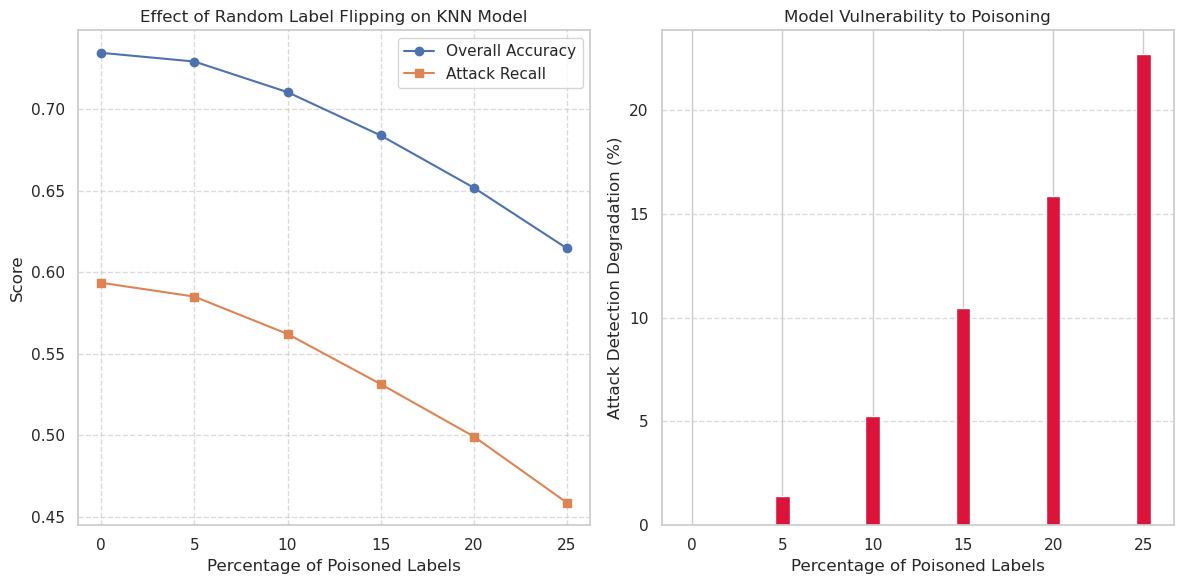

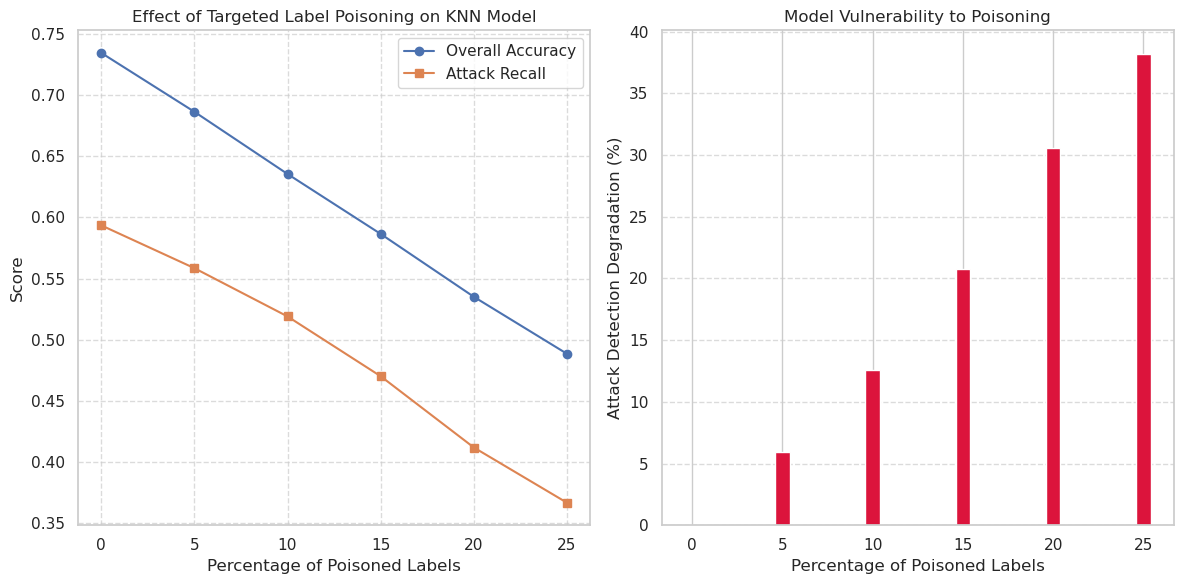

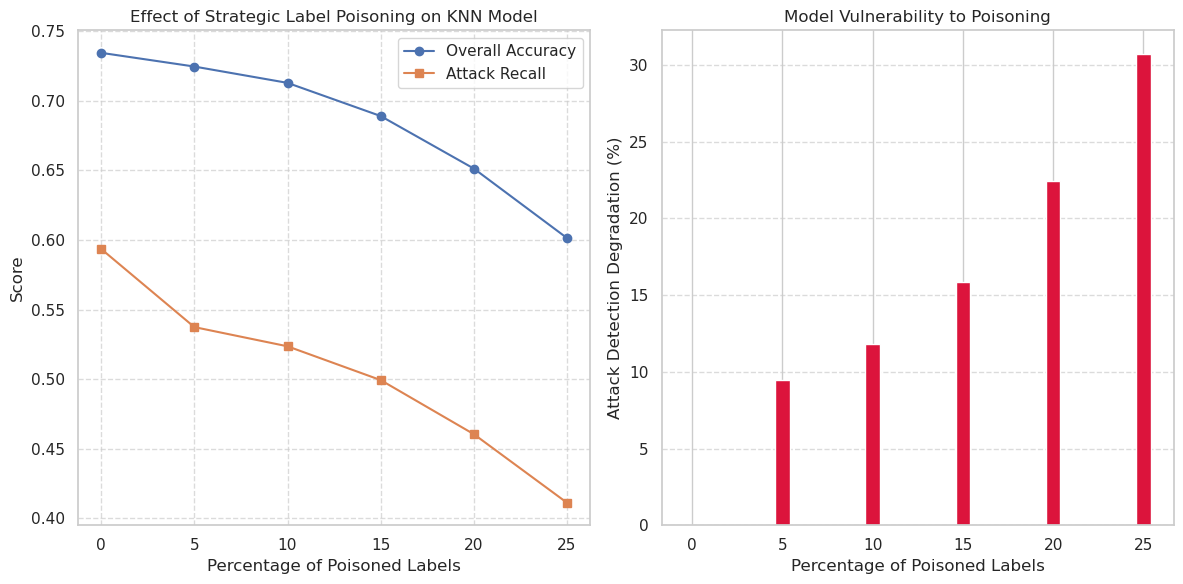


Comparing poisoning strategies knn...


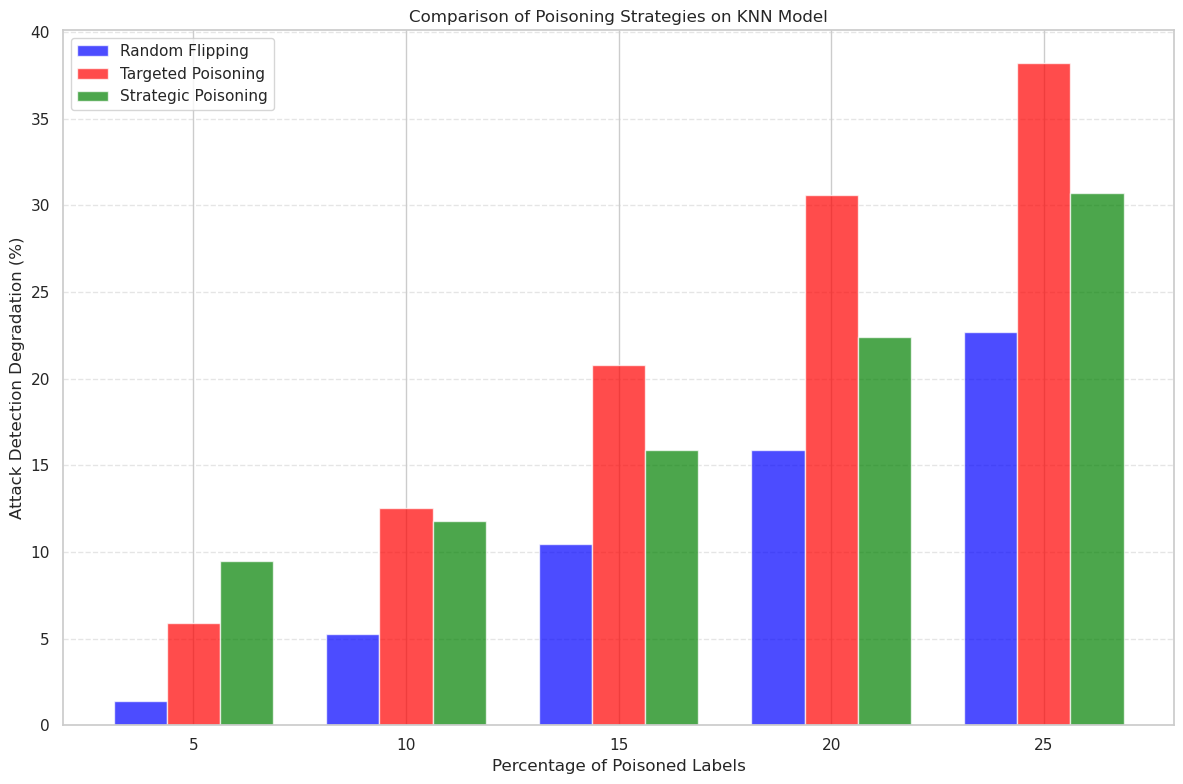


Evaluating models with random label flipping...
Training rf model on clean data...
[ColumnTransformer] ........... (1 of 1) Processing num, total=   0.0s


/home/shroudedsublet/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1509: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Clean model evaluation - Accuracy: 0.8934, Attack Recall: 0.7331
Training rf model on 5% poisoned data...
[ColumnTransformer] ........... (1 of 1) Processing num, total=   0.1s


/home/shroudedsublet/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1509: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


5% poisoned model - Accuracy: 0.8873, Attack Recall: 0.7264
Training rf model on 10% poisoned data...
[ColumnTransformer] ........... (1 of 1) Processing num, total=   0.1s


...

15% poisoned model - Accuracy: 0.8624, Attack Recall: 0.6579
Training rf model on 20% poisoned data...
[ColumnTransformer] ........... (1 of 1) Processing num, total=   0.0s


/home/shroudedsublet/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1509: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


20% poisoned model - Accuracy: 0.8409, Attack Recall: 0.6368
Training rf model on 25% poisoned data...
[ColumnTransformer] ........... (1 of 1) Processing num, total=   0.0s


/home/shroudedsublet/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1509: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


25% poisoned model - Accuracy: 0.8151, Attack Recall: 0.6113

Plotting results...


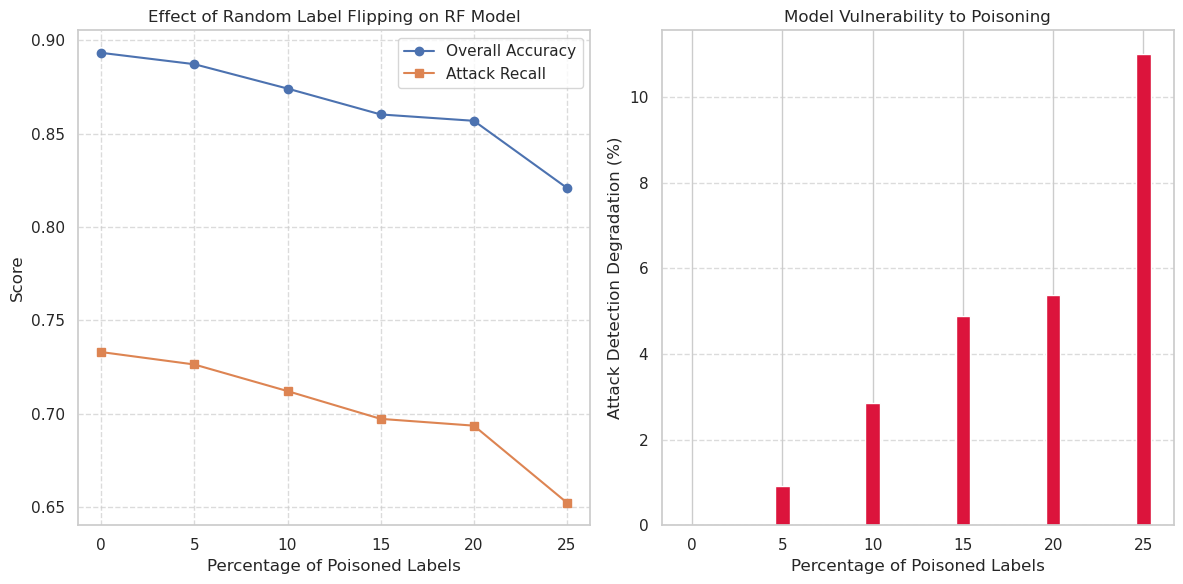

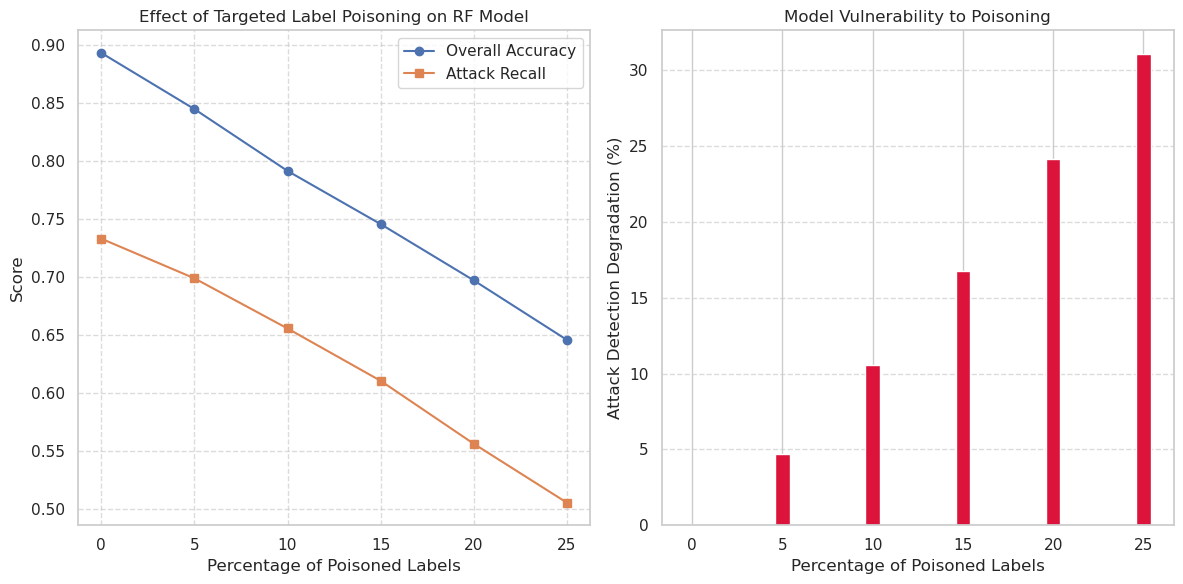

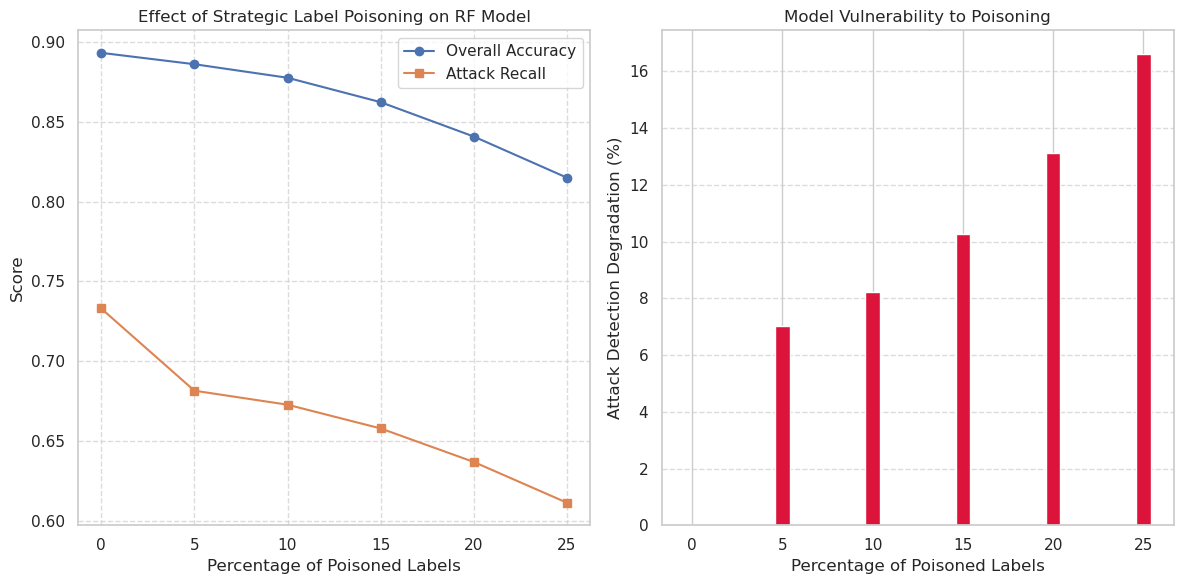


Comparing poisoning strategies knn...


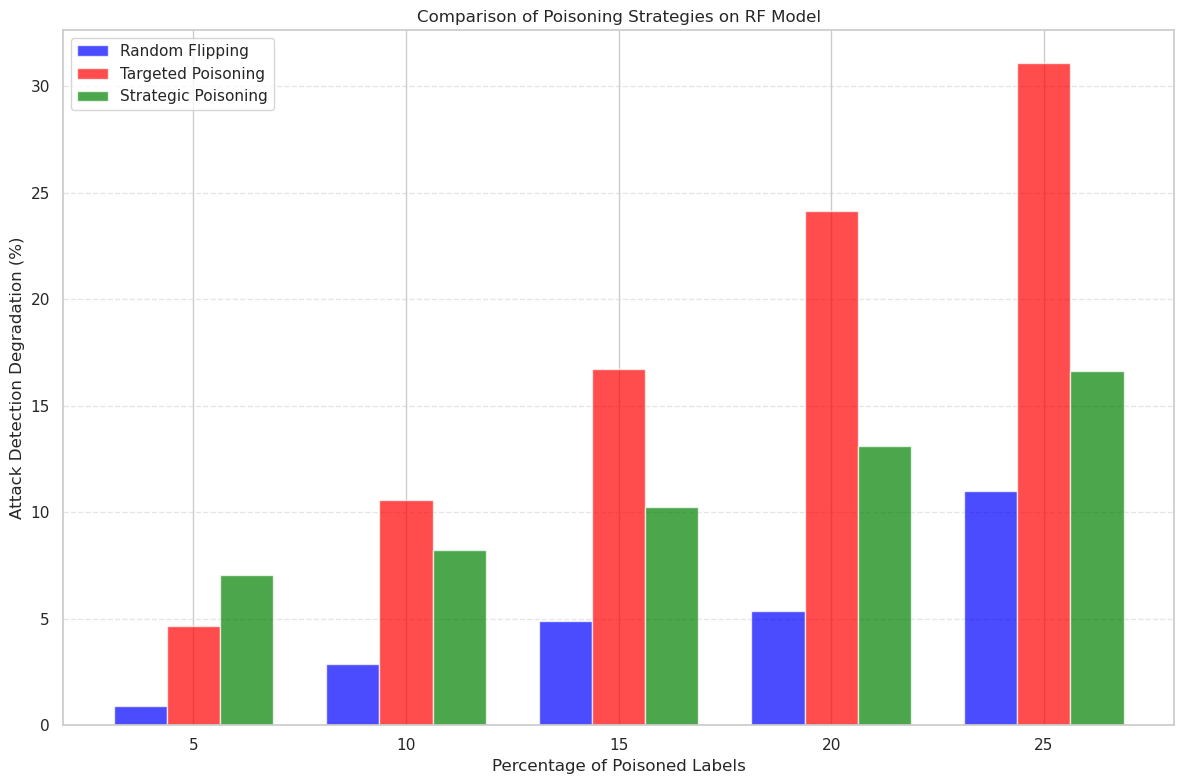


Evaluating models with random label flipping...
Training sgd model on clean data...
[ColumnTransformer] ........... (1 of 1) Processing num, total=   0.1s


/home/shroudedsublet/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_stochastic_gradient.py:723: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/home/shroudedsublet/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1509: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Clean model evaluation - Accuracy: 0.4209, Attack Recall: 0.3482
Training sgd model on 5% poisoned data...
[ColumnTransformer] ........... (1 of 1) Processing num, total=   0.0s


/home/shroudedsublet/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_stochastic_gradient.py:723: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/home/shroudedsublet/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1509: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


5% poisoned model - Accuracy: 0.4362, Attack Recall: 0.3223
Training sgd model on 10% poisoned data...
[ColumnTransformer] ........... (1 of 1) Processing num, total=   0.1s


...

15% poisoned model - Accuracy: 0.4313, Attack Recall: 0.2639
Training sgd model on 20% poisoned data...
[ColumnTransformer] ........... (1 of 1) Processing num, total=   0.0s


/home/shroudedsublet/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_stochastic_gradient.py:723: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/home/shroudedsublet/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1509: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


20% poisoned model - Accuracy: 0.3622, Attack Recall: 0.2045
Training sgd model on 25% poisoned data...
[ColumnTransformer] ........... (1 of 1) Processing num, total=   0.0s


/home/shroudedsublet/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_stochastic_gradient.py:723: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/home/shroudedsublet/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1509: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


25% poisoned model - Accuracy: 0.3694, Attack Recall: 0.2079

Plotting results...


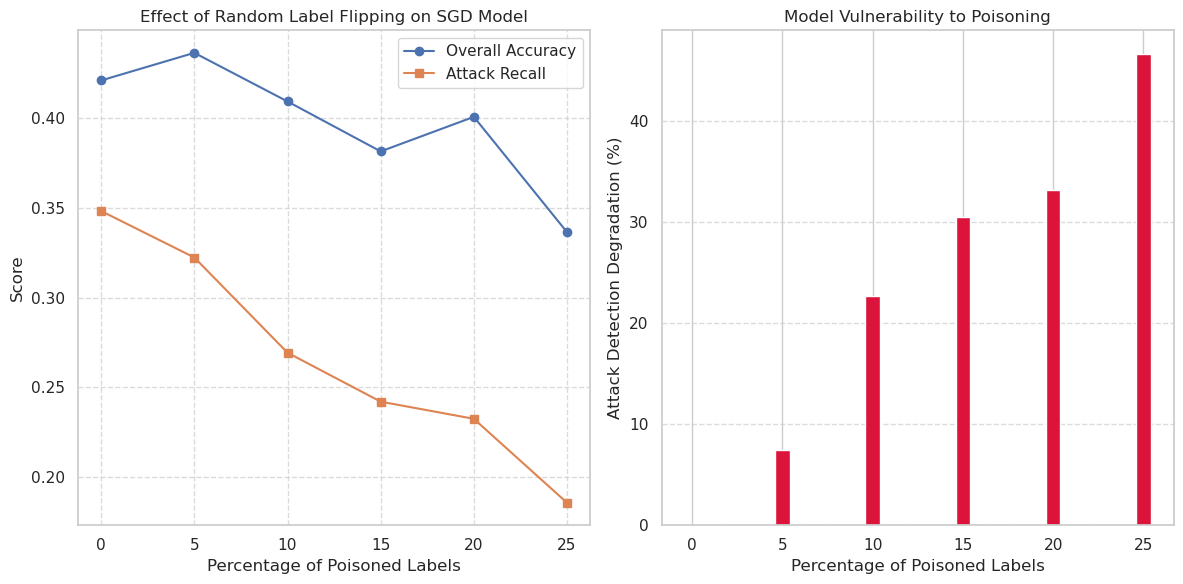

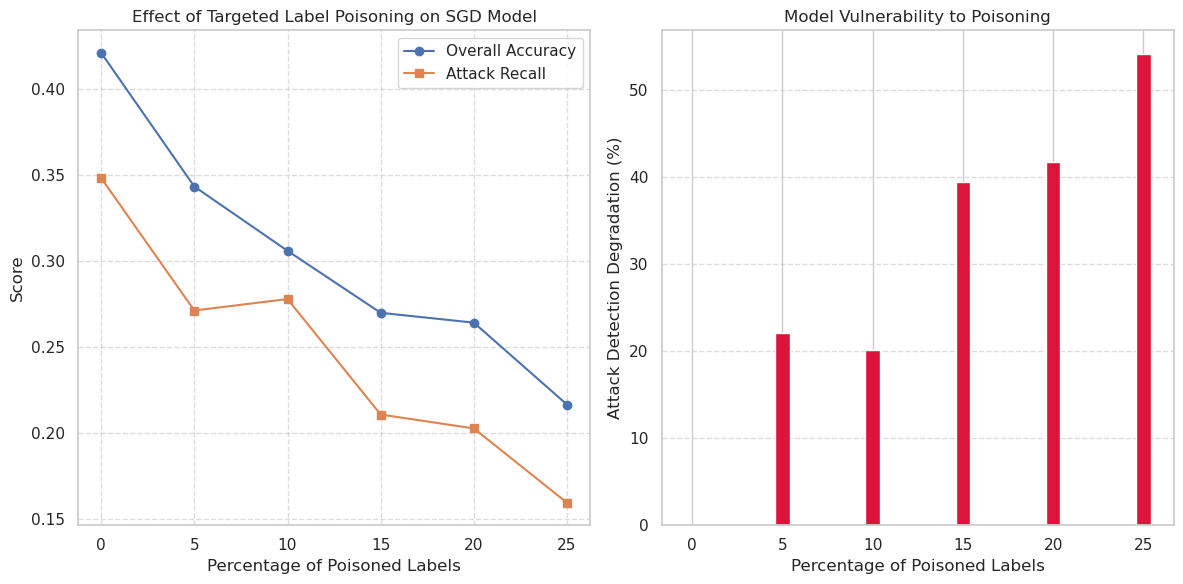

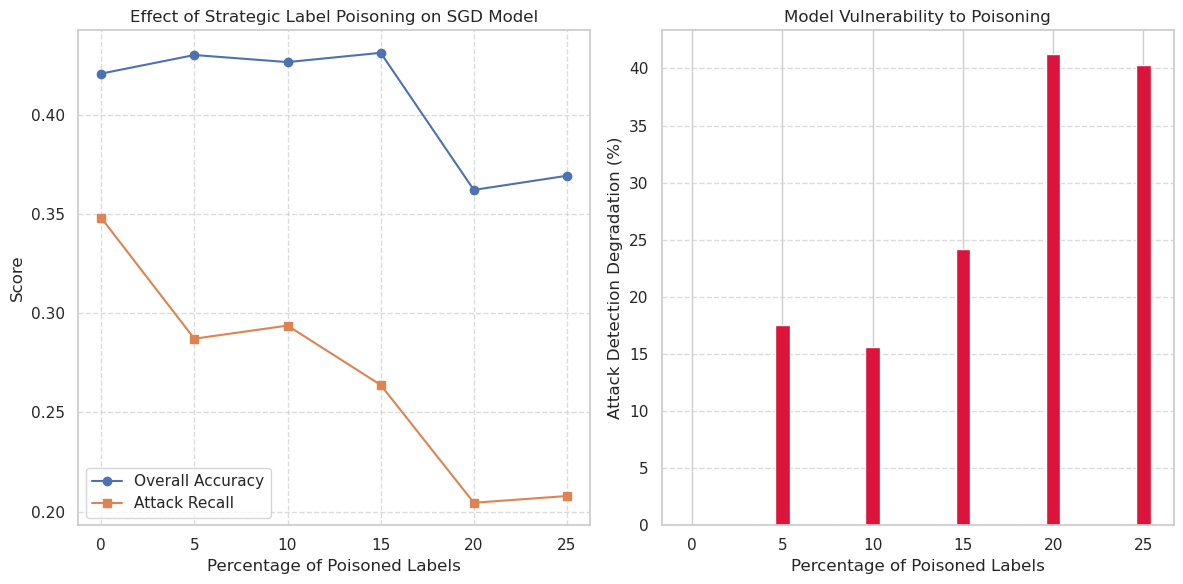


Comparing poisoning strategies knn...


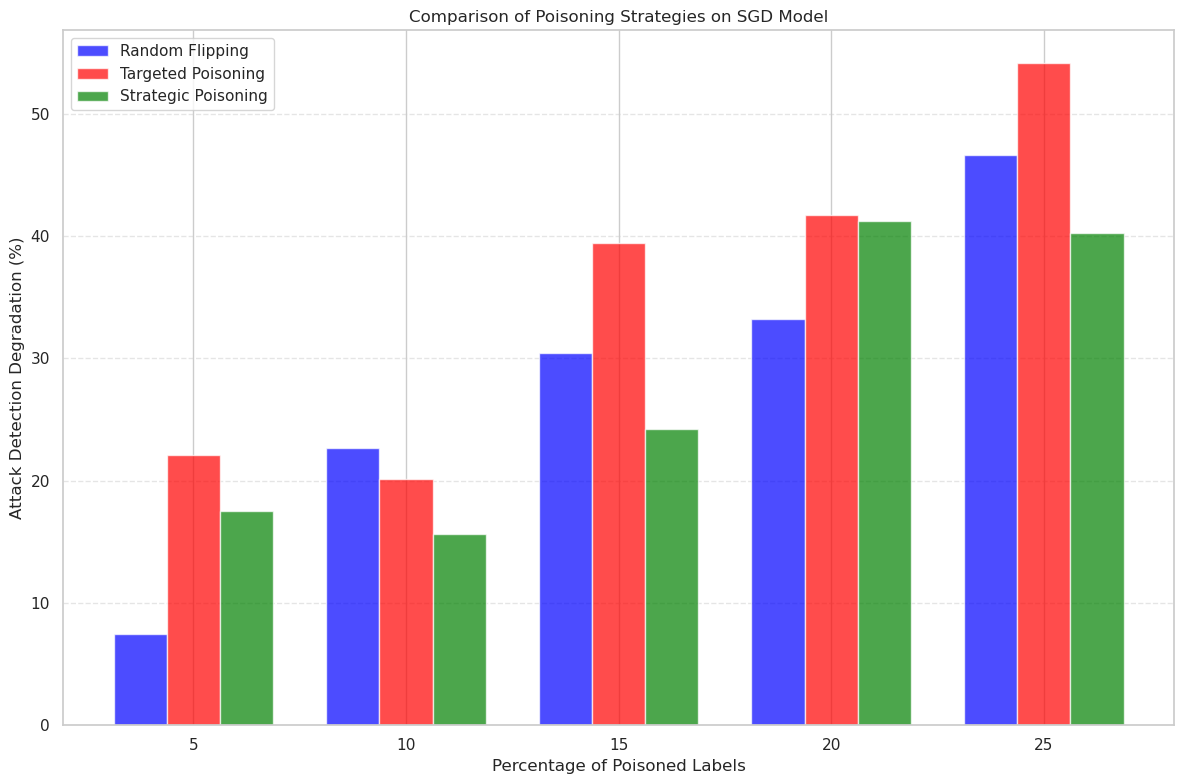


Evaluating models with random label flipping...
Training mlp model on clean data...
[ColumnTransformer] ........... (1 of 1) Processing num, total=   0.0s


/home/shroudedsublet/anaconda3/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (15) reached and the optimization hasn't converged yet.
  warnings.warn(
/home/shroudedsublet/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1509: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Clean model evaluation - Accuracy: 0.7011, Attack Recall: 0.5613
Training mlp model on 5% poisoned data...
[ColumnTransformer] ........... (1 of 1) Processing num, total=   0.1s


/home/shroudedsublet/anaconda3/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (15) reached and the optimization hasn't converged yet.
  warnings.warn(
/home/shroudedsublet/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1509: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


5% poisoned model - Accuracy: 0.6881, Attack Recall: 0.5433
Training mlp model on 10% poisoned data...
[ColumnTransformer] ........... (1 of 1) Processing num, total=   0.1s


...

15% poisoned model - Accuracy: 0.6745, Attack Recall: 0.4760
Training mlp model on 20% poisoned data...
[ColumnTransformer] ........... (1 of 1) Processing num, total=   0.1s


/home/shroudedsublet/anaconda3/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (15) reached and the optimization hasn't converged yet.
  warnings.warn(
/home/shroudedsublet/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1509: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


20% poisoned model - Accuracy: 0.6495, Attack Recall: 0.4498
Training mlp model on 25% poisoned data...
[ColumnTransformer] ........... (1 of 1) Processing num, total=   0.0s


/home/shroudedsublet/anaconda3/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (15) reached and the optimization hasn't converged yet.
  warnings.warn(
/home/shroudedsublet/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1509: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


25% poisoned model - Accuracy: 0.6098, Attack Recall: 0.4096

Plotting results...


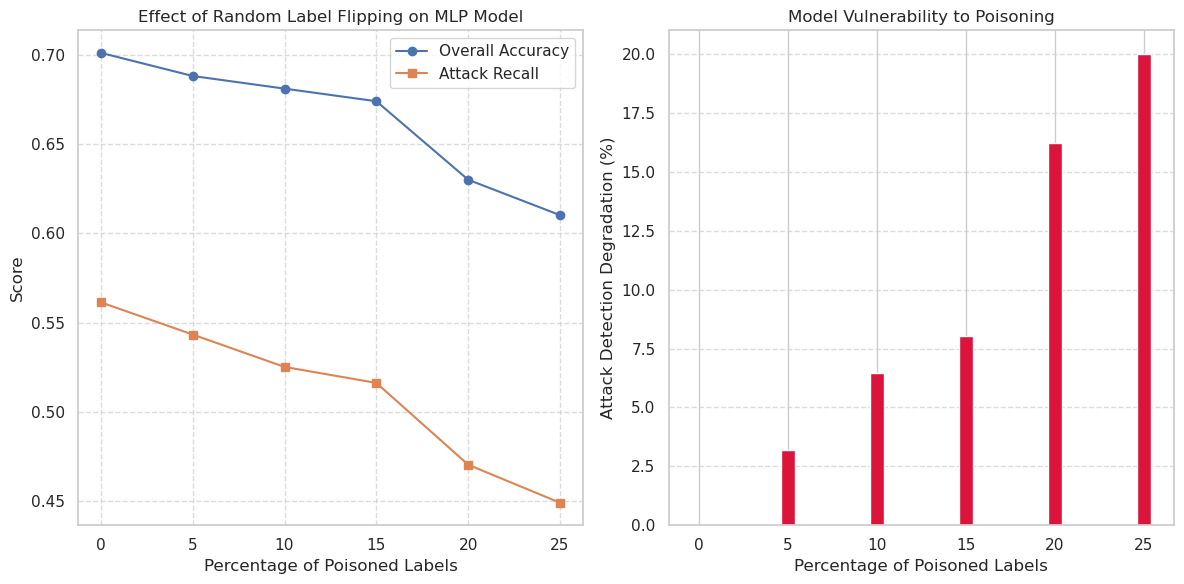

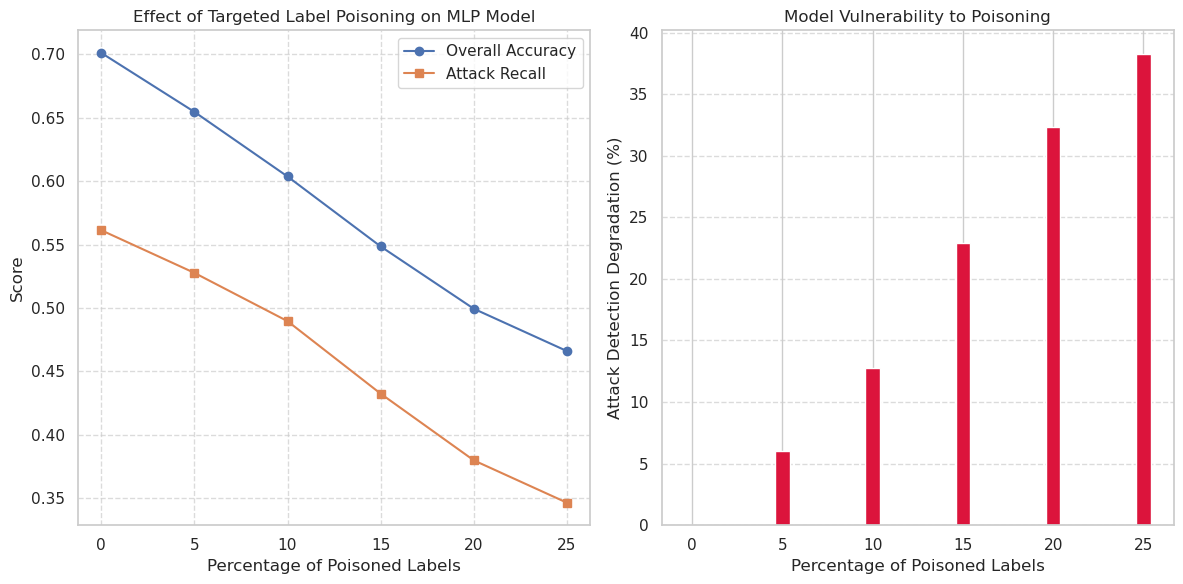

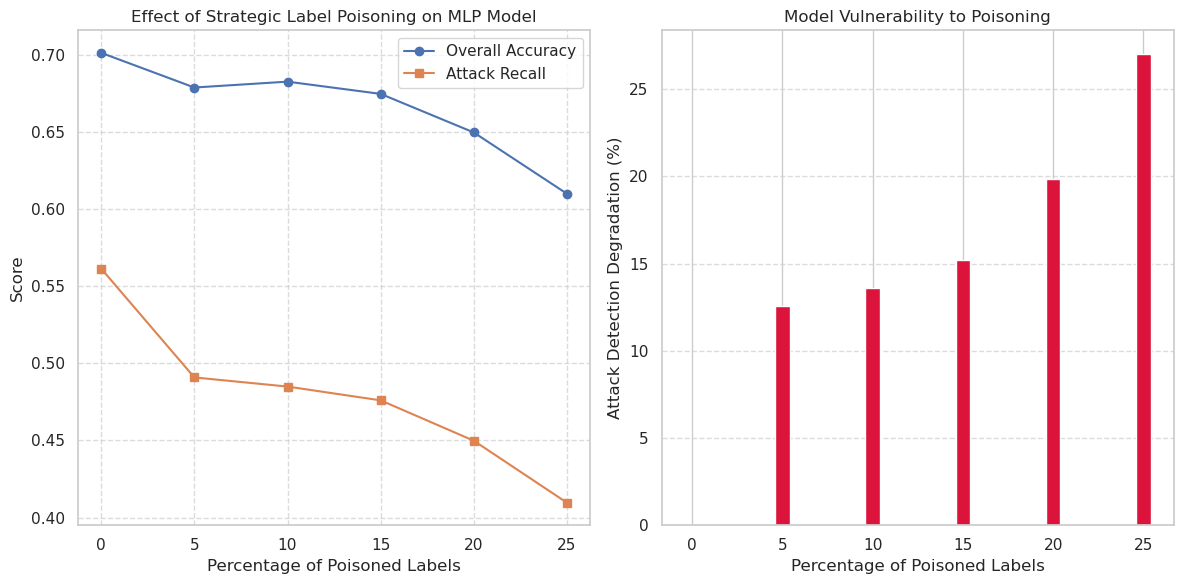


Comparing poisoning strategies knn...


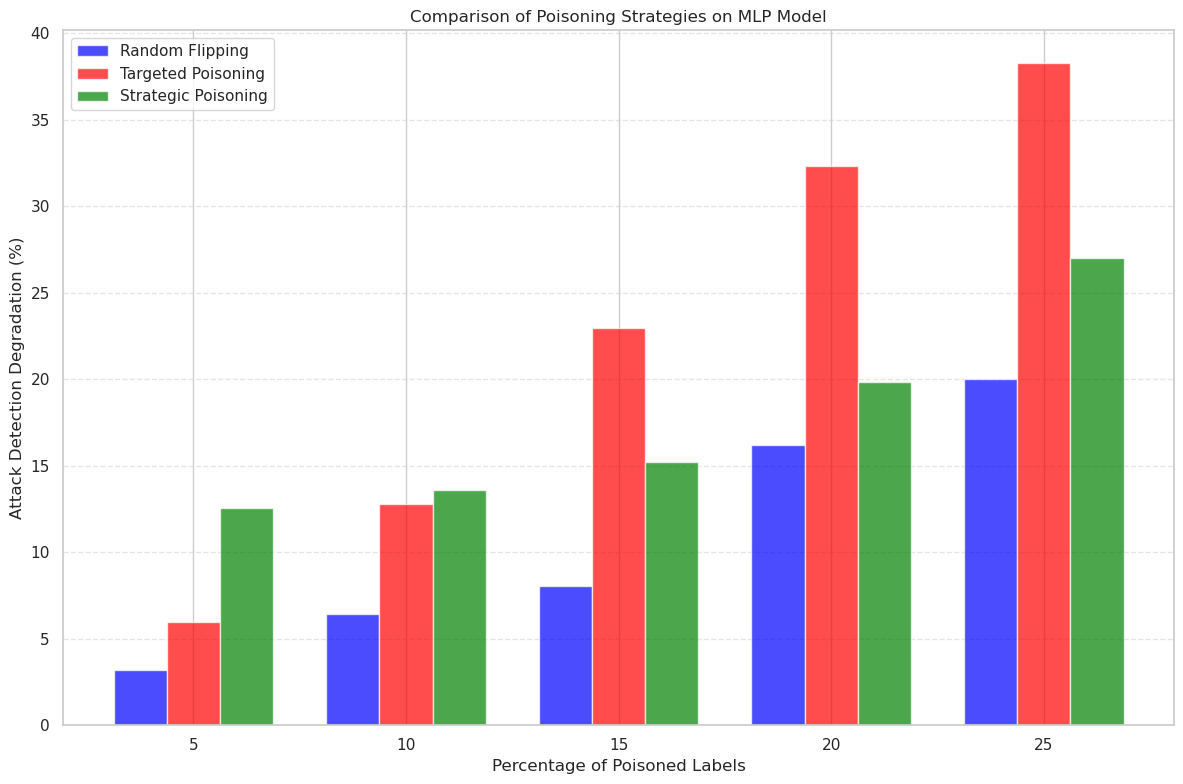

In [34]:
def implement_label_poisoning_analysis(df, percentages=[0, 5, 10, 15, 20, 25]):
    # Preprocess the data
    print("Preprocessing data...")
    X_train, X_test, y_train, y_test, X, y = preprocess_data(df)
    
    # Build preprocessor
    print("Building preprocessor...")
    preprocessor = build_preprocessor(X_train)
    
    # Train original model
    print("Training original model for reference...")
    _, _, _, original_model = train_model(X_train, y_train, preprocessor)
    
    # Create dictionary with clean labels
    clean_labels = {0: y_train.copy()}
    
    # Implement random label flipping
    print("\nImplementing random label flipping...")
    random_labels = random_label_flipping(y_train, percentages=[p for p in percentages if p != 0])
    random_labels.update(clean_labels)  # Add clean labels
    
    # Implement targeted label poisoning
    print("\nImplementing targeted label poisoning...")
    targeted_labels = targeted_label_poisoning(y_train, X_train, original_model, percentages=[p for p in percentages if p != 0])
    targeted_labels.update(clean_labels)  # Add clean labels
    
    # Implement strategic label poisoning
    print("\nImplementing strategic label poisoning...")
    strategic_labels = strategic_label_poisoning(y_train, X_train, original_model, percentages=[p for p in percentages if p != 0])
    strategic_labels.update(clean_labels)  # Add clean labels

    
    # Evaluate models with different poisoning strategies
    print("\nEvaluating models with random label flipping...")
    random_results = evaluate_poisoned_models(X_train, X_test, y_test, preprocessor, random_labels, model_type='knn')
    
    print("\nEvaluating models with targeted label poisoning...")
    targeted_results = evaluate_poisoned_models(X_train, X_test, y_test, preprocessor, targeted_labels, model_type='knn')
    
    print("\nEvaluating models with strategic label poisoning...")
    strategic_results = evaluate_poisoned_models(X_train, X_test, y_test, preprocessor, strategic_labels, model_type='knn')
    
    # Plot results
    print("\nPlotting results...")
    
    plot_results(random_results, "Random Label Flipping", "knn")
    plot_results(targeted_results, "Targeted Label Poisoning", "knn")
    plot_results(strategic_results, "Strategic Label Poisoning", "knn")

    # Compare strategies
    print("\nComparing poisoning strategies knn...")
    compare_poisoning_strategies(random_results, targeted_results, strategic_results, "knn")
    
    # Evaluate models with different poisoning strategies
    print("\nEvaluating models with random label flipping...")
    random_results = evaluate_poisoned_models(X_train, X_test, y_test, preprocessor, random_labels, model_type='rf')
    
    print("\nEvaluating models with targeted label poisoning...")
    targeted_results = evaluate_poisoned_models(X_train, X_test, y_test, preprocessor, targeted_labels, model_type='rf')
    
    print("\nEvaluating models with strategic label poisoning...")
    strategic_results = evaluate_poisoned_models(X_train, X_test, y_test, preprocessor, strategic_labels, model_type='rf')
    
    # Plot results
    print("\nPlotting results...")
    
    plot_results(random_results, "Random Label Flipping", "rf")
    plot_results(targeted_results, "Targeted Label Poisoning", "rf")
    plot_results(strategic_results, "Strategic Label Poisoning", "rf")

    # Compare strategies
    print("\nComparing poisoning strategies knn...")
    compare_poisoning_strategies(random_results, targeted_results, strategic_results, "rf")
    
    # Evaluate models with different poisoning strategies
    print("\nEvaluating models with random label flipping...")
    random_results = evaluate_poisoned_models(X_train, X_test, y_test, preprocessor, random_labels, model_type='sgd')
    
    print("\nEvaluating models with targeted label poisoning...")
    targeted_results = evaluate_poisoned_models(X_train, X_test, y_test, preprocessor, targeted_labels, model_type='sgd')
    
    print("\nEvaluating models with strategic label poisoning...")
    strategic_results = evaluate_poisoned_models(X_train, X_test, y_test, preprocessor, strategic_labels, model_type='sgd')
    # Plot results
    print("\nPlotting results...")
    
    plot_results(random_results, "Random Label Flipping", "sgd")
    plot_results(targeted_results, "Targeted Label Poisoning", "sgd")
    plot_results(strategic_results, "Strategic Label Poisoning", "sgd")

    # Compare strategies
    print("\nComparing poisoning strategies knn...")
    compare_poisoning_strategies(random_results, targeted_results, strategic_results, "sgd")
    
    # Evaluate models with different poisoning strategies
    print("\nEvaluating models with random label flipping...")
    random_results = evaluate_poisoned_models(X_train, X_test, y_test, preprocessor, random_labels, model_type='mlp')
    
    print("\nEvaluating models with targeted label poisoning...")
    targeted_results = evaluate_poisoned_models(X_train, X_test, y_test, preprocessor, targeted_labels, model_type='mlp')
    
    print("\nEvaluating models with strategic label poisoning...")
    strategic_results = evaluate_poisoned_models(X_train, X_test, y_test, preprocessor, strategic_labels, model_type='mlp')
    
    # Plot results
    print("\nPlotting results...")

    plot_results(random_results, "Random Label Flipping", "mlp")
    plot_results(targeted_results, "Targeted Label Poisoning", "mlp")
    plot_results(strategic_results, "Strategic Label Poisoning", "mlp")

    # Compare strategies
    print("\nComparing poisoning strategies knn...")
    compare_poisoning_strategies(random_results, targeted_results, strategic_results, "mlp")

    return random_results, targeted_results, strategic_results

random_results, targeted_results, strategic_results = implement_label_poisoning_analysis(df)